In [ ]:
import os

# Root of the artifact tree (mean activations, head scores, eval runs).
# Override with FV_STORAGE_ROOT; otherwise resolves relative to the repo root.
STORAGE_ROOT = os.environ.get("FV_STORAGE_ROOT", "storage")


Plot saved successfully as eval_with_averages.png


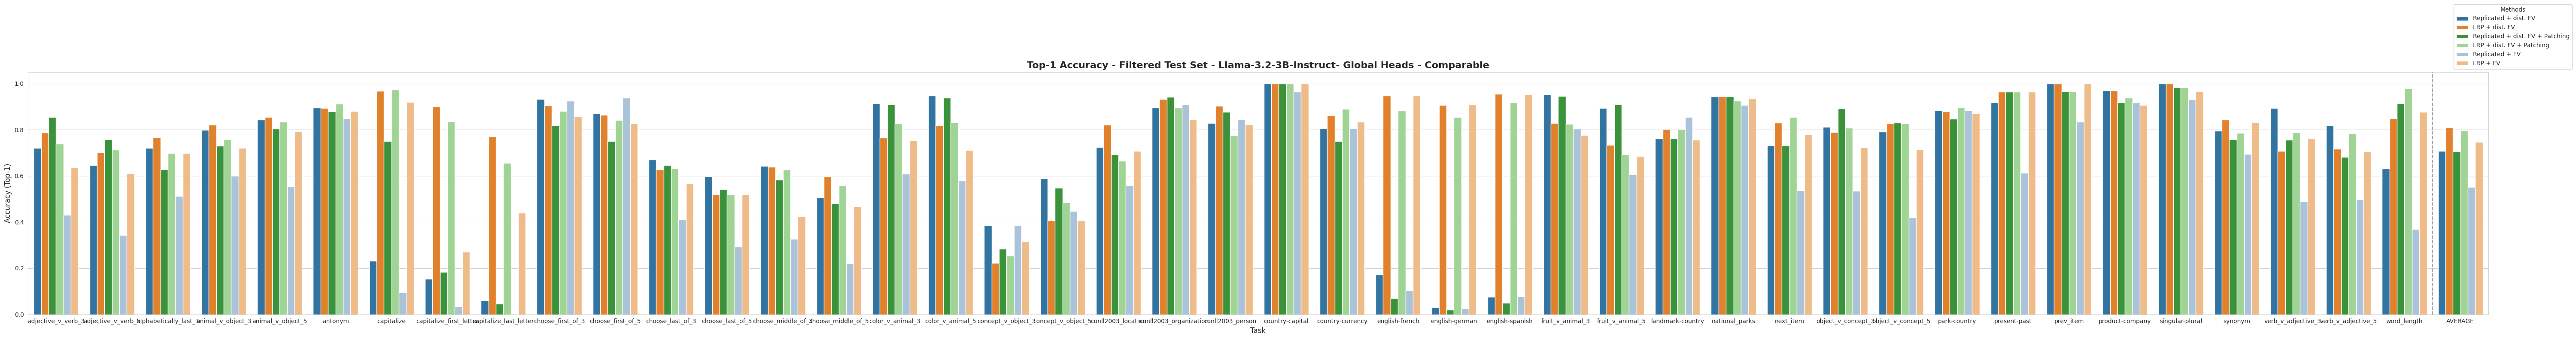

In [17]:
import json
import glob
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def plot_evaluation_results(
    file_paths,
    method_map=None,
    method_order=None,
    color_palette=None,
    output_name="eval_results.png"
):
    """
    Parses JSON files and plots Top-1 accuracy per task AND the overall average.
    """
    data_list = []

    for path in file_paths:
        try:
            with open(path, 'r') as f:
                data = json.load(f)

            parts = path.split(os.sep)
            task_name = parts[-2]
            raw_run_name = os.path.splitext(parts[-1])[0]

            # 1. Apply renaming if map is provided
            display_name = method_map.get(raw_run_name, raw_run_name) if method_map else raw_run_name

            # 2. Extract Top-1 Accuracy
            topk_data = data.get('intervention_topk', {})
            if not topk_data: continue

            first_key = list(topk_data.keys())[0]
            top1_accuracy = topk_data[first_key][0][1]

            data_list.append({
                'Task': task_name,
                'Method': display_name,
                'Top-1 Accuracy': top1_accuracy
            })
        except Exception as e:
            print(f"Error processing {path}: {e}")

    df = pd.DataFrame(data_list)
    if df.empty:
        print("No data found.")
        return

    # 3. Filter by the provided order (if applicable)
    if method_order:
        df = df[df['Method'].isin(method_order)]

    # --- NEW: Calculate Average across all tasks ---
    avg_df = df.groupby('Method')['Top-1 Accuracy'].mean().reset_index()
    avg_df['Task'] = 'AVERAGE'

    # Combine individual results with the average
    combined_df = pd.concat([df, avg_df], ignore_index=True)

    # Ensure Method order for the legend and bars
    if method_order:
        combined_df['Method'] = pd.Categorical(
            combined_df['Method'], categories=method_order, ordered=True
        )

    # Ensure Task order so 'AVERAGE' appears at the end
    all_tasks = sorted([t for t in df['Task'].unique() if t != 'AVERAGE']) + ['AVERAGE']
    combined_df['Task'] = pd.Categorical(combined_df['Task'], categories=all_tasks, ordered=True)
    combined_df = combined_df.sort_values(['Task', 'Method'])

    # 4. Plotting
    plt.figure(figsize=(60, 8))
    sns.set_style("whitegrid")

    plot = sns.barplot(
        data=combined_df,
        x='Task',
        y='Top-1 Accuracy',
        hue='Method',
        palette=color_palette,
        hue_order=method_order
    )

    # Visual distinction for the Average group
    plt.axvline(x=len(all_tasks) - 1.5, color='gray', linestyle='--', alpha=0.7)

    plt.title('Top-1 Accuracy - Filtered Test Set - Llama-3.2-3B-Instruct- Global Heads - Comparable', fontsize=16, fontweight='bold')
    plt.ylim(0, 1.05)
    plt.ylabel('Accuracy (Top-1)', fontsize=12)
    plt.xlabel('Task', fontsize=12)
    plt.legend(bbox_to_anchor=(1.01, 1), loc='lower center', title='Methods', frameon=True)

    plt.tight_layout()
    plt.savefig(output_name, dpi=300)
    print(f"Plot saved successfully as {output_name}")
    plt.show()

# --- Configuration ---

my_method_map_patching = {
    "prompt_dist_lrp_averaged_scale1.0": "LRP + dist. FV",
    "prompt_fv_lrp_averaged_editlayer11_scale1.0": "LRP + FV",
    "prompt_dist_ie_averaged_scale1.0": "Replicated + dist. FV",
    "prompt_fv_ie_averaged_editlayer9_scale1.0": "Replicated + FV",
    "prompt_dist_lrp_averaged_scale1.0_patching": "LRP + dist. FV + Patching",
    "prompt_dist_ie_averaged_scale1.0_patching": "Replicated + dist. FV + Patching",


}


my_method_map_old = {
    "prompt_dist_lrp_scale1.0_old11": "LRP + dist. FV",
    "prompt_fv_lrp_editlayer11_scale1.0_old11": "LRP + FV",
    "prompt_dist_task_aie_scale1.0_old11": "Replicated + dist. FV",
    "prompt_fv_task_aie_editlayer11_scale1.0_old11": "Replicated + FV",


}

my_method_map_average = {
    "prompt_dist_lrp_averaged_scale1.0": "LRP + dist. FV",
    "prompt_fv_lrp_averaged_editlayer11_scale1.0": "LRP + FV",
    "prompt_dist_ie_averaged_scale1.0": "Replicated + dist. FV",
    "prompt_fv_ie_averaged_editlayer11_scale1.0": "Replicated + FV",


}

my_method_map_average_comp = {
    "prompt_dist_lrp_averaged_scale1.0_n5_lqp": "LRP + dist. FV",
    "prompt_fv_lrp_averaged_editlayer11_scale1.0_n5_lqp": "LRP + FV",
    "prompt_dist_lrp_averaged_scale1.0": "LRP all rel. + dist. FV",
    "prompt_fv_lrp_averaged_editlayer11_scale1.0": "LRP all rel. + FV",


}

my_method_map_pt = {
    "prompt_dist_lrp_per_task_scale1.0": "LRP + dist. FV",
    "prompt_fv_lrp_per_task_editlayer11_scale1.0": "LRP + FV",
    "prompt_dist_ie_per_task_scale1.0": "Replicated + dist. FV",
    "prompt_fv_ie_per_task_editlayer11_scale1.0": "Replicated + FV",


}

my_method_map_qp = {
    "prompt_dist_lrp_averaged_scale1.0": "LRP + dist. FV",
    "prompt_fv_lrp_averaged_editlayer11_scale1.0": "LRP + FV",
    "prompt_dist_lrp_averaged_scale1.0_all_qp": "LRP + dist. FV + all query position",
    "prompt_fv_lrp_averaged_editlayer11_scale1.0_all_qp": "LRP + FV + all query position",


}

my_method_map_qp_pt = {
    "prompt_dist_lrp_per_task_scale1.0": "LRP + dist. FV",
    "prompt_fv_lrp_per_task_editlayer11_scale1.0": "LRP + FV",
    "prompt_dist_lrp_per_task_scale1.0_all_qp": "LRP + dist. FV + all query position",
    "prompt_fv_lrp_per_task_editlayer11_scale1.0_all_qp": "LRP + FV + all query position",


}


my_order = ["Replicated + dist. FV", "LRP + dist. FV","Replicated + dist. FV + Patching","LRP + dist. FV + Patching", "Replicated + FV", "LRP + FV"]

#my_order = ["Replicated + FV","Replicated + dist. FV"]

#my_order = ["Replicated + dist. FV", "LRP + dist. FV", "Replicated + FV", "LRP + FV"]

#my_order = [ "LRP + dist. FV",  "LRP + FV"]
#my_order = [ "LRP + dist. FV", "LRP + dist. FV + all query position", "LRP + FV","LRP + FV + all query position"]
#my_order = ["LRP all rel. + dist. FV", "LRP + dist. FV", "LRP all rel. + FV", "LRP + FV"]



my_colors = {
    # Distilled Pair (Original Blue/Orange)
    "Replicated + dist. FV":           "#1f77b4",  # Dark Blue
    "LRP + dist. FV":                  "#ff7f0e",  # Dark Orange

    # Patching Pair (New Green family)
    "Replicated + dist. FV + Patching": "#2ca02c",  # Dark Green
    "LRP + dist. FV + Patching":        "#98df8a",  # Light Green

    #"LRP + dist. FV + all query position": "#2ca02c",  # Dark Green
    #"LRP + FV + all query position":        "#98df8a",  # Light Green

    #"LRP all rel. + dist. FV": "#2ca02c",  # Dark Green
    #"LRP all rel. + FV":        "#98df8a",  # Light Green

    # Standard Pair (Lighter Blue/Orange)
    "Replicated + FV":                 "#a2c4e1",  # Light Blue
    "LRP + FV":                        "#ffbb78"   # Light Orange
}

# --- Execution ---
#base_dir = f"{STORAGE_ROOT}/eval/results/"
base_dir = f"{STORAGE_ROOT}/eval/Llama-3.2-3B-Instruct"
#base_dir = f"{STORAGE_ROOT}/eval/Qwen3-4B-Instruct-2507"
#base_dir = f"{STORAGE_ROOT}/eval8b/Llama-3.1-8B-Instruct"
all_json_files = glob.glob(os.path.join(base_dir, "**/*.json"), recursive=True)

plot_evaluation_results(
    file_paths=all_json_files,
    method_map=my_method_map_patching,
    method_order=my_order,
    color_palette=my_colors,
    output_name="eval_with_averages.png"
)


/tmp/ipykernel_1425707/1880988290.py:98: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left', title='Methods', frameon=True, fontsize=12)


Plot saved successfully as eval_labeled_final.png


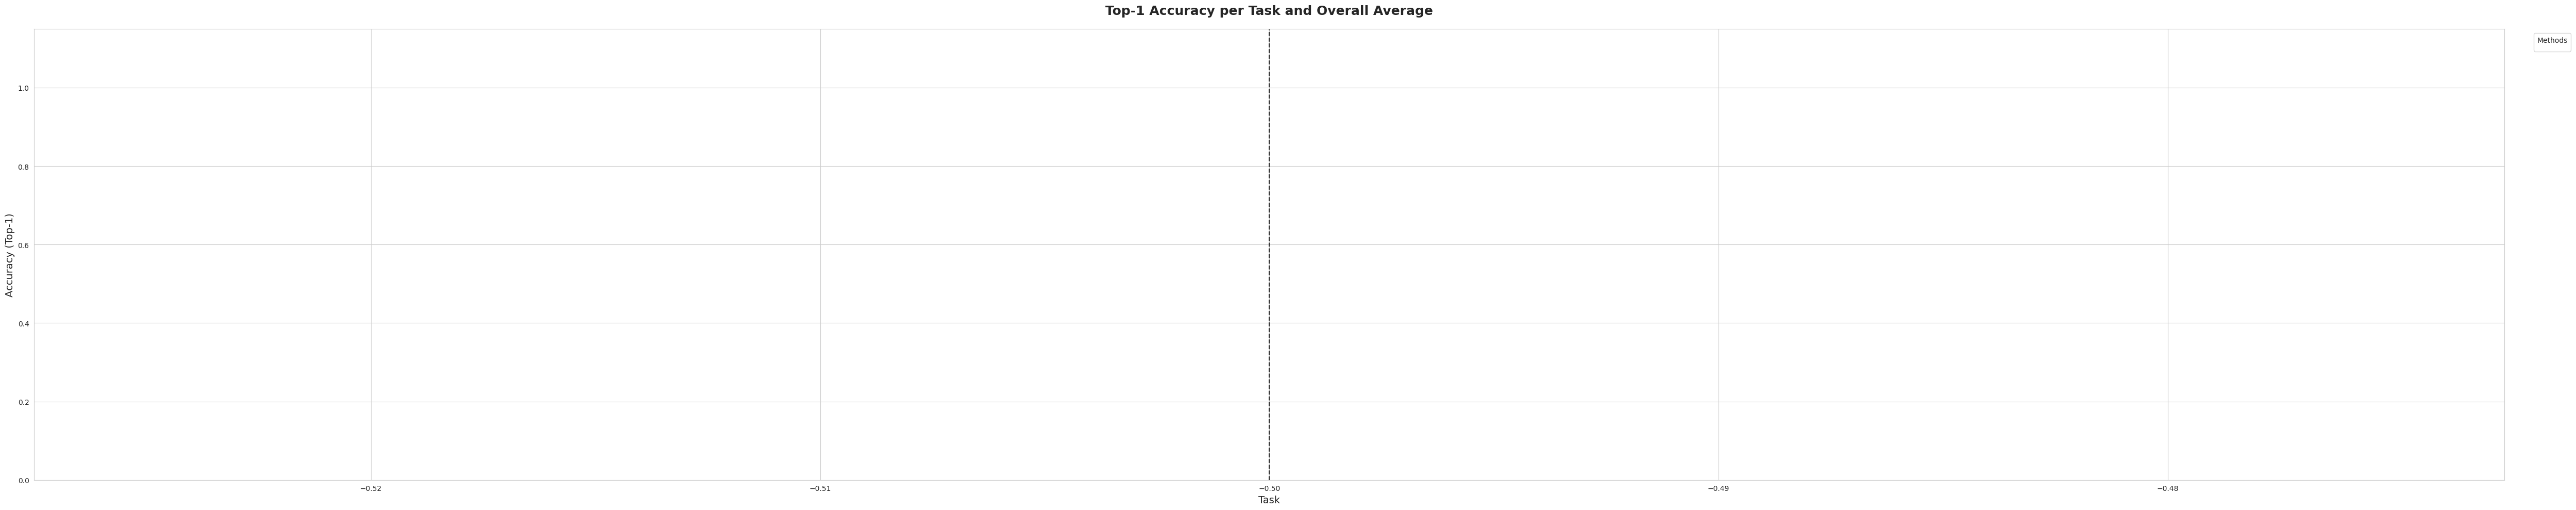

In [24]:
import json
import glob
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def plot_evaluation_results(
    file_paths,
    method_map=None,
    method_order=None,
    color_palette=None,
    output_name="eval_results.png"
):
    """
    Parses JSON files and plots Top-1 accuracy with values displayed on top of bars.
    """
    data_list = []

    for path in file_paths:
        try:
            with open(path, 'r') as f:
                data = json.load(f)

            parts = path.split(os.sep)
            task_name = parts[-2]
            raw_run_name = os.path.splitext(parts[-1])[0]

            display_name = method_map.get(raw_run_name, raw_run_name) if method_map else raw_run_name

            topk_data = data.get('intervention_topk', {})
            if not topk_data: continue

            first_key = list(topk_data.keys())[0]
            top1_accuracy = topk_data[first_key][0][1]

            data_list.append({
                'Task': task_name,
                'Method': display_name,
                'Top-1 Accuracy': top1_accuracy
            })
        except Exception as e:
            print(f"Error processing {path}: {e}")

    df = pd.DataFrame(data_list)
    if df.empty:
        print("No data found.")
        return

    if method_order:
        df = df[df['Method'].isin(method_order)]

    # Calculate Average
    avg_df = df.groupby('Method', observed=True)['Top-1 Accuracy'].mean().reset_index()
    avg_df['Task'] = 'AVERAGE'

    combined_df = pd.concat([df, avg_df], ignore_index=True)

    if method_order:
        combined_df['Method'] = pd.Categorical(
            combined_df['Method'], categories=method_order, ordered=True
        )

    all_tasks = sorted([t for t in df['Task'].unique() if t != 'AVERAGE']) + ['AVERAGE']
    combined_df['Task'] = pd.Categorical(combined_df['Task'], categories=all_tasks, ordered=True)
    combined_df = combined_df.sort_values(['Task', 'Method'])

    # Plotting
    plt.figure(figsize=(50, 10)) # Increased width for better label spacing
    sns.set_style("whitegrid")

    ax = sns.barplot(
        data=combined_df,
        x='Task',
        y='Top-1 Accuracy',
        hue='Method',
        palette=color_palette,
        hue_order=method_order
    )

    # --- NEW: Add labels on top of bars ---
    for container in ax.containers:
        ax.bar_label(
            container,
            fmt='%.4f',      # 3 decimal places
            padding=3,       # Distance from top of bar
            fontsize=9,
            fontweight='bold',
            rotation=45      # Rotated for readability if bars are narrow
        )

    plt.axvline(x=len(all_tasks) - 1.5, color='black', linestyle='--', linewidth=1.5, alpha=0.8)

    plt.title('Top-1 Accuracy per Task and Overall Average', fontsize=18, fontweight='bold', pad=20)
    plt.ylim(0, 1.15) # Increased limit to accommodate labels
    plt.ylabel('Accuracy (Top-1)', fontsize=14)
    plt.xlabel('Task', fontsize=14)
    plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left', title='Methods', frameon=True, fontsize=12)

    plt.tight_layout()
    plt.savefig(output_name, dpi=300)
    print(f"Plot saved successfully as {output_name}")
    plt.show()

# --- Execution ---




plot_evaluation_results(
    file_paths=all_json_files,
    method_map=my_method_map,
    method_order=my_order,
    color_palette=my_colors,
    output_name="eval_labeled_final.png"
)



In [1]:
import os
import sys
import torch

# Resolve the repo root so `import utils` works from a notebooks/ subdir
# Get the absolute path of the parent directory
parent_dir = os.path.abspath('..')

# Add it to sys.path if it isn't already there
if parent_dir not in sys.path:
    sys.path.insert(0, parent_dir)

from eval.utils import load_prompt_aie, load_prompt_cie, select_modules

# ─── CONFIGURATION ────────────────────────────────────────────────────────────
STORAGE_ROOT = os.environ.get("FV_STORAGE_ROOT", "storage")
# Define your two root directories for comparison
ROOT_DIR_1 = os.path.join(STORAGE_ROOT, "function_vectors", "full_results_prompt_based_short")
ROOT_DIR_2 = os.path.join(STORAGE_ROOT, "function_vectors", "full_results_prompt_based_short")

MODEL_SHORT = "Llama-3.2-3B-Instruct"

# Selection methods (e.g., "lrp", "task_aie").
# If you are just comparing two different runs of the same method, keep these identical.
SELECTION_1 = "task_aie"
SELECTION_2 = "lrp"

TOPK_ATTN = 20

TASKS = [
    "antonym", "capitalize", "country-capital",
    "country-currency", "english-french", "english-german", "english-spanish",
    "landmark-country", "national_parks", "park-country",
    "present-past", "product-company",
    "singular-plural", "synonym",
]

# ─── UTILITIES ────────────────────────────────────────────────────────────────

def calculate_overlap(heads_1, heads_2):
    """Returns the intersection set and the overlap percentage."""
    set1, set2 = set(heads_1), set(heads_2)
    intersection = set1.intersection(set2)
    overlap_pct = (len(intersection) / max(len(set1), 1)) * 100
    return intersection, overlap_pct

def format_heads(head_list):
    """Formats a list of (Layer, Head) tuples for readable printing."""
    # Sort by Layer, then Head
    sorted_heads = sorted(list(head_list), key=lambda x: (x[0], x[1]))
    return ", ".join([f"L{l}H{h}" for l, h in sorted_heads])

# ─── MAIN SCRIPT ──────────────────────────────────────────────────────────────

def main():
    print(f"Comparing top {TOPK_ATTN} heads between:")
    print(f"  Path 1: {ROOT_DIR_1} (Selection: {SELECTION_1})")
    print(f"  Path 2: {ROOT_DIR_2} (Selection: {SELECTION_2})\n")

    # 1. GLOBAL HEAD COMPARISON (Macro-averaged across all tasks)
    print("=" * 80)
    print(" GLOBAL MACRO-AVERAGED HEADS (Used for actual steering in eval)")
    print("=" * 80)

    try:
        aie_1 = load_prompt_aie(ROOT_DIR_1, MODEL_SHORT, TASKS, SELECTION_1)
        aie_2 = load_prompt_aie(ROOT_DIR_2, MODEL_SHORT, TASKS, SELECTION_2)

        global_heads_1, _ = select_modules(aie_1, topk_attn=TOPK_ATTN)
        global_heads_2, _ = select_modules(aie_2, topk_attn=TOPK_ATTN)

        global_intersection, global_pct = calculate_overlap(global_heads_1, global_heads_2)

        print(f"\n[Path 1 Global Heads]:\n  {format_heads(global_heads_1)}")
        print(f"\n[Path 2 Global Heads]:\n  {format_heads(global_heads_2)}")
        print(f"\n[Intersection] ({len(global_intersection)}/{TOPK_ATTN} -> {global_pct:.1f}% Overlap):")
        print(f"  {format_heads(global_intersection)}\n")

    except Exception as e:
        print(f"[Error] Failed to calculate global heads: {e}\n")


    # 2. PER-TASK HEAD COMPARISON
    print("=" * 80)
    print(" PER-TASK HEAD COMPARISON")
    print("=" * 80)

    for task in TASKS:
        try:
            cie_1 = load_prompt_cie(ROOT_DIR_1, MODEL_SHORT, task, SELECTION_1)
            cie_2 = load_prompt_cie(ROOT_DIR_2, MODEL_SHORT, task, SELECTION_2)

            task_heads_1, _ = select_modules(cie_1, topk_attn=TOPK_ATTN)
            task_heads_2, _ = select_modules(cie_2, topk_attn=TOPK_ATTN)

            intersection, overlap_pct = calculate_overlap(task_heads_1, task_heads_2)

            print(f"Task: **{task}**")
            print(f"  Path 1 : {format_heads(task_heads_1)}")
            print(f"  Path 2 : {format_heads(task_heads_2)}")
            print(f"  Overlap: {len(intersection)}/{TOPK_ATTN} ({overlap_pct:.1f}%) -> {format_heads(intersection)}\n")

        except FileNotFoundError:
            print(f"Task: **{task}** -> [Missing files in one or both directories. Skipping.]\n")
        except Exception as e:
            print(f"Task: **{task}** -> [Error: {e}]\n")

if __name__ == "__main__":
    main()

Comparing top 20 heads between:
  Path 1: ${FV_STORAGE_ROOT}/function_vectors/full_results_prompt_based_short (Selection: task_aie)
  Path 2: ${FV_STORAGE_ROOT}/function_vectors/full_results_prompt_based_short (Selection: lrp)

 GLOBAL MACRO-AVERAGED HEADS (Used for actual steering in eval)

[Path 1 Global Heads]:
  L11H7, L12H3, L12H6, L12H16, L12H17, L12H22, L12H23, L13H9, L13H11, L13H18, L13H19, L13H23, L14H5, L14H6, L14H16, L14H20, L15H3, L15H4, L19H1, L27H11

[Path 2 Global Heads]:
  L9H23, L11H7, L12H2, L12H3, L12H6, L12H11, L12H16, L12H17, L13H2, L13H9, L13H11, L13H18, L13H19, L14H9, L14H11, L14H16, L14H17, L14H20, L15H17, L18H1

[Intersection] (11/20 -> 55.0% Overlap):
  L11H7, L12H3, L12H6, L12H16, L12H17, L13H9, L13H11, L13H18, L13H19, L14H16, L14H20

 PER-TASK HEAD COMPARISON
Task: **antonym**
  Path 1 : L6H4, L6H20, L8H11, L9H10, L9H14, L9H22, L9H23, L11H3, L11H7, L12H15, L12H16, L12H17, L13H5, L13H11, L13H18, L13H23, L14H6, L15H4, L18H6, L19H19
  Path 2 : L6H4, L7H7, L8H11

In [2]:
# ─── UTILITIES ────────────────────────────────────────────────────────────────
TASKS = [
    # abstractive
    "antonym", "capitalize", "capitalize_first_letter", "capitalize_last_letter", "capitalize_second_letter",
    "country-capital", "country-currency", "english-french", "english-german", "english-spanish",
    "landmark-country", "lowercase_first_letter", "lowercase_last_letter", "national_parks",
    "next_capital_letter", "next_item", "park-country", "present-past", "prev_item",
    "product-company", "singular-plural", "synonym", "word_length",
    # extractive
    "adjective_v_verb_3", "adjective_v_verb_5",
    #"alphabetically_first_3",
    "alphabetically_first_5",
    "alphabetically_last_3", "alphabetically_last_5",
    "animal_v_object_3", "animal_v_object_5",
    "choose_first_of_3", "choose_first_of_5",
    "choose_last_of_3", "choose_last_of_5",
    "choose_middle_of_3", "choose_middle_of_5",
    "color_v_animal_3", "color_v_animal_5",
    "concept_v_object_3", "concept_v_object_5",
    "conll2003_location", "conll2003_organization", "conll2003_person",
    "fruit_v_animal_3", "fruit_v_animal_5",
    "object_v_concept_3", "object_v_concept_5",
    #"squad_val",
    "verb_v_adjective_3", "verb_v_adjective_5",
]
def calculate_overlap(heads_1, heads_2):
    """Returns the intersection set and the overlap percentage."""
    set1, set2 = set(heads_1), set(heads_2)
    intersection = set1.intersection(set2)
    overlap_pct = (len(intersection) / max(len(set1), 1)) * 100
    return intersection, overlap_pct

def format_heads(head_list):
    """Formats a list of (Layer, Head) tuples for readable printing."""
    sorted_heads = sorted(list(head_list), key=lambda x: (x[0], x[1]))
    return ", ".join([f"L{l}H{h}" for l, h in sorted_heads])

# ─── MAIN SCRIPT ──────────────────────────────────────────────────────────────

def main():
    print(f"Comparing top {TOPK_ATTN} GLOBAL heads between:")
    print(f"  Path 1: {ROOT_DIR_1} (Selection: {SELECTION_1})")
    print(f"  Path 2: {ROOT_DIR_2} (Selection: {SELECTION_2})\n")

    try:
        # Load the macro-averaged attention indirect effects across all tasks
        aie_1 = load_prompt_aie(ROOT_DIR_1, MODEL_SHORT, TASKS, SELECTION_1)
        aie_2 = load_prompt_aie(ROOT_DIR_2, MODEL_SHORT, TASKS, SELECTION_2)

        # Select the top K modules globally
        global_heads_1, _ = select_modules(aie_1, topk_attn=TOPK_ATTN)
        global_heads_2, _ = select_modules(aie_2, topk_attn=TOPK_ATTN)

        # Calculate overlap
        intersection, overlap_pct = calculate_overlap(global_heads_1, global_heads_2)

        print("-" * 65)
        print(f"[Path 1 Global Heads]:\n  {format_heads(global_heads_1)}\n")
        print(f"[Path 2 Global Heads]:\n  {format_heads(global_heads_2)}")
        print("-" * 65)
        print(f"OVERLAP METRICS:")
        print(f"  Intersection Size: {len(intersection)} / {TOPK_ATTN}")
        print(f"  Overlap Percent:   {overlap_pct:.1f}%")
        print(f"  Shared Heads:      {format_heads(intersection)}")
        print("-" * 65)

    except Exception as e:
        print(f"[Error] Failed to calculate global heads: {e}\n")

if __name__ == "__main__":
    main()

Comparing top 20 GLOBAL heads between:
  Path 1: ${FV_STORAGE_ROOT}/function_vectors/full_results_prompt_based_short (Selection: task_aie)
  Path 2: ${FV_STORAGE_ROOT}/function_vectors/full_results_prompt_based_short (Selection: lrp)

  [warn] missing prompt IE for 'capitalize_second_letter', skipping
  [warn] missing prompt IE for 'lowercase_first_letter', skipping
  [warn] missing prompt IE for 'lowercase_last_letter', skipping
  [warn] missing prompt IE for 'next_capital_letter', skipping
  [warn] missing prompt IE for 'alphabetically_first_5', skipping
  [warn] missing prompt IE for 'alphabetically_last_5', skipping
  [warn] missing prompt IE for 'capitalize_second_letter', skipping
  [warn] missing prompt IE for 'lowercase_first_letter', skipping
  [warn] missing prompt IE for 'lowercase_last_letter', skipping
  [warn] missing prompt IE for 'next_capital_letter', skipping
  [warn] missing prompt IE for 'alphabetically_first_5', skipping
  [warn] missing prompt IE for 'alphabetical

In [3]:
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# Resolve the repo root so `import utils` works from a notebooks/ subdir
# Get the absolute path of the parent directory
parent_dir = os.path.abspath('..')

# Add it to sys.path if it isn't already there
if parent_dir not in sys.path:
    sys.path.insert(0, parent_dir)

from eval.utils import load_prompt_aie, load_prompt_cie, select_modules

# ─── CONFIGURATION ────────────────────────────────────────────────────────────
STORAGE_ROOT = os.environ.get("FV_STORAGE_ROOT", "storage")
# Define your two root directories for comparison
ROOT_DIR_1 = os.path.join(STORAGE_ROOT, "function_vectors", "full_results_prompt_based_short")
ROOT_DIR_2 = os.path.join(STORAGE_ROOT, "function_vectors", "full_results_prompt_based_short")

MODEL_SHORT = "Llama-3.2-3B-Instruct"

# Selection methods (e.g., "lrp", "task_aie").
# If you are just comparing two different runs of the same method, keep these identical.
SELECTION_1 = "task_aie"
SELECTION_2 = "lrp"

TOPK_ATTN = 20

# Architecture config for the plot (Llama-3.2-3B is 28 layers, 24 heads)
MODEL_LAYERS = 28
MODEL_HEADS = 24




Comparing top 20 GLOBAL heads between:
  Path 1: ${FV_STORAGE_ROOT}/function_vectors/full_results_prompt_based_short (Selection: task_aie)
  Path 2: ${FV_STORAGE_ROOT}/function_vectors/full_results_prompt_based_short (Selection: lrp)

  [warn] missing prompt IE for 'capitalize_second_letter', skipping
  [warn] missing prompt IE for 'lowercase_first_letter', skipping
  [warn] missing prompt IE for 'lowercase_last_letter', skipping
  [warn] missing prompt IE for 'next_capital_letter', skipping
  [warn] missing prompt IE for 'alphabetically_first_5', skipping
  [warn] missing prompt IE for 'alphabetically_last_5', skipping
  [warn] missing prompt IE for 'capitalize_second_letter', skipping
  [warn] missing prompt IE for 'lowercase_first_letter', skipping
  [warn] missing prompt IE for 'lowercase_last_letter', skipping
  [warn] missing prompt IE for 'next_capital_letter', skipping
  [warn] missing prompt IE for 'alphabetically_first_5', skipping
  [warn] missing prompt IE for 'alphabetical

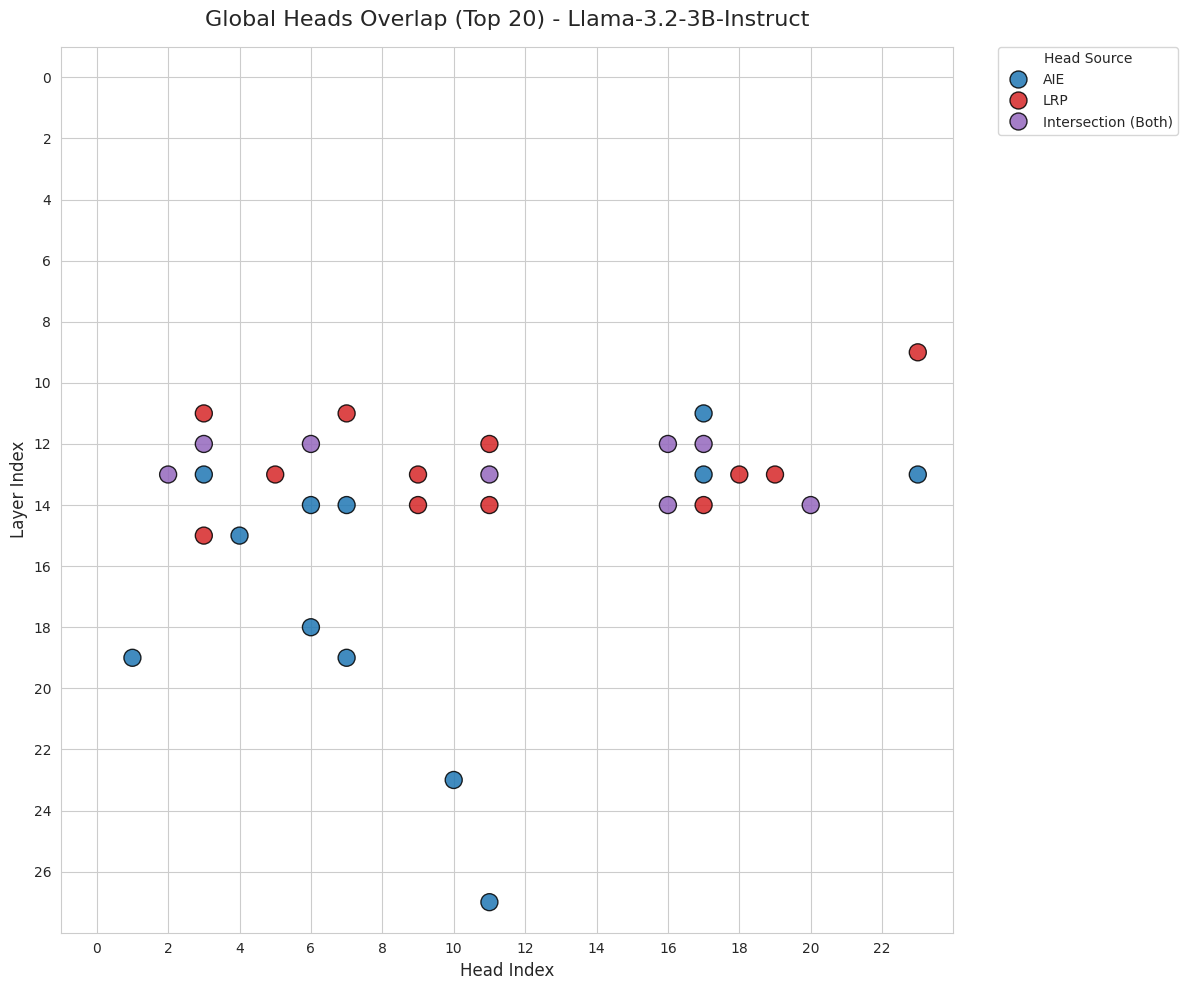

In [4]:


# Architecture config for the plot
MODEL_LAYERS = 28
MODEL_HEADS = 24

TASKS = [
    # abstractive
    "antonym", "capitalize", "capitalize_first_letter", "capitalize_last_letter", "capitalize_second_letter",
    "country-capital", "country-currency", "english-french", "english-german", "english-spanish",
    "landmark-country", "lowercase_first_letter", "lowercase_last_letter", "national_parks",
    "next_capital_letter", "next_item", "park-country", "present-past", "prev_item",
    "product-company", "singular-plural", "synonym", "word_length",
    # extractive
    "adjective_v_verb_3", "adjective_v_verb_5",
    "alphabetically_first_5",
    "alphabetically_last_3", "alphabetically_last_5",
    "animal_v_object_3", "animal_v_object_5",
    "choose_first_of_3", "choose_first_of_5",
    "choose_last_of_3", "choose_last_of_5",
    "choose_middle_of_3", "choose_middle_of_5",
    "color_v_animal_3", "color_v_animal_5",
    "concept_v_object_3", "concept_v_object_5",
    "conll2003_location", "conll2003_organization", "conll2003_person",
    "fruit_v_animal_3", "fruit_v_animal_5",
    "object_v_concept_3", "object_v_concept_5",
    "verb_v_adjective_3", "verb_v_adjective_5",
]

# ─── UTILITIES ────────────────────────────────────────────────────────────────

def calculate_overlap(heads_1, heads_2):
    """Returns the intersection set and the overlap percentage."""
    set1, set2 = set(heads_1), set(heads_2)
    intersection = set1.intersection(set2)
    overlap_pct = (len(intersection) / max(len(set1), 1)) * 100
    return intersection, overlap_pct

def format_heads_sorted(head_list):
    """Formats a list of (Layer, Head) tuples alphabetically for readable printing."""
    sorted_heads = sorted(list(head_list), key=lambda x: (x[0], x[1]))
    return ", ".join([f"L{l}H{h}" for l, h in sorted_heads])

def print_ranked_heads(head_list, title):
    """Prints the heads in the exact order they were provided (highest score first)."""
    print(f"\n{title} (Highest to Lowest Score):")
    # Group them into a single string for compact viewing, but keep the rank visible
    ranked_str = ", ".join([f"#{i+1}: L{l}H{h}" for i, (l, h) in enumerate(head_list)])
    print(f"  {ranked_str}")

def plot_global_heads_atlas(heads_1, heads_2, label_1="Path 1", label_2="Path 2",
                            depth=MODEL_LAYERS, width=MODEL_HEADS, title="Global Heads Atlas"):
    """Plots the global heads, highlighting the intersection."""
    set1, set2 = set(heads_1), set(heads_2)
    intersection = set1.intersection(set2)
    only_1 = set1 - intersection
    only_2 = set2 - intersection

    data = []
    for l, h in only_1:
        data.append({'Layer': l, 'Head': h, 'Source': label_1})
    for l, h in only_2:
        data.append({'Layer': l, 'Head': h, 'Source': label_2})
    for l, h in intersection:
        data.append({'Layer': l, 'Head': h, 'Source': 'Intersection (Both)'})

    df = pd.DataFrame(data)

    if df.empty:
        print("No heads to plot!")
        return

    plt.figure(figsize=(12, 10))
    sns.set_style("whitegrid")

    palette = {
        label_1: '#1f77b4',
        label_2: '#d62728',
        'Intersection (Both)': '#9467bd'
    }

    sns.scatterplot(
        data=df,
        x='Head',
        y='Layer',
        hue='Source',
        s=150,
        alpha=0.85,
        palette=palette,
        edgecolor='black'
    )

    plt.title(title, fontsize=16, pad=15)
    plt.xlim(-1, width)
    plt.ylim(depth, -1)
    plt.xticks(range(0, width, 2))
    plt.yticks(range(0, depth, 2))
    plt.xlabel("Head Index", fontsize=12)
    plt.ylabel("Layer Index", fontsize=12)

    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0., title="Head Source")
    plt.tight_layout()
    plt.show()

# ─── MAIN SCRIPT ──────────────────────────────────────────────────────────────

def main():
    print(f"Comparing top {TOPK_ATTN} GLOBAL heads between:")
    print(f"  Path 1: {ROOT_DIR_1} (Selection: {SELECTION_1})")
    print(f"  Path 2: {ROOT_DIR_2} (Selection: {SELECTION_2})\n")

    try:
        # Load the macro-averaged attention indirect effects across all tasks
        aie_1 = load_prompt_aie(ROOT_DIR_1, MODEL_SHORT, TASKS, SELECTION_1)
        aie_2 = load_prompt_aie(ROOT_DIR_2, MODEL_SHORT, TASKS, SELECTION_2)

        # Select the top K modules globally. This natively returns them in ranked order!
        global_heads_1, _ = select_modules(aie_1, topk_attn=TOPK_ATTN)
        global_heads_2, _ = select_modules(aie_2, topk_attn=TOPK_ATTN)

        print("-" * 80)
        print(" RANKED ORDER (Highest Importance to Lowest)")
        print("-" * 80)
        print_ranked_heads(global_heads_1, "[Path 1]")
        print_ranked_heads(global_heads_2, "[Path 2]")
        print("\n")

        # Calculate overlap (using sets, so order is lost here)
        intersection, overlap_pct = calculate_overlap(global_heads_1, global_heads_2)

        print("-" * 80)
        print(" OVERLAP METRICS")
        print("-" * 80)
        print(f"  Intersection Size: {len(intersection)} / {TOPK_ATTN}")
        print(f"  Overlap Percent:   {overlap_pct:.1f}%")
        print(f"  Shared Heads:      {format_heads_sorted(intersection)}")
        print("-" * 80)

        # Plot the heads
        plot_title = f"Global Heads Overlap (Top {TOPK_ATTN}) - {MODEL_SHORT}"
        plot_global_heads_atlas(
            global_heads_1,
            global_heads_2,
            label_1="AIE",
            label_2="LRP",
            title=plot_title
        )

    except Exception as e:
        print(f"[Error] Failed to calculate and plot global heads: {e}\n")

if __name__ == "__main__":
    main()

Plot saved successfully as llama8b_layer_sweep_averaged_scale1.pdf


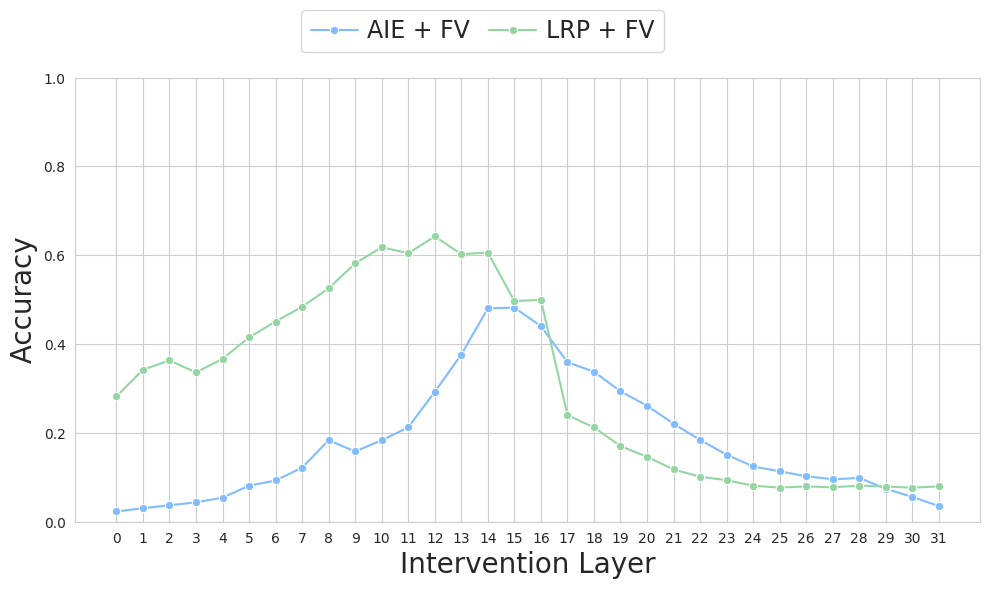

In [10]:
import json
import glob
import os
import re
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def plot_layer_sweep(
    file_paths,
    method_map=None,
    output_name="layer_sweep_averaged_scale1.png"
):
    """
    Parses JSON files, extracts the layer number, calculates the average
    Top-1 accuracy across all tasks, and strictly plots only the mapped methods.
    """
    data_list = []

    for path in file_paths:
        try:
            with open(path, 'r') as f:
                data = json.load(f)

            parts = path.split(os.sep)
            task_name = parts[-2]
            raw_run_name = os.path.splitext(parts[-1])[0]

            # 1. Extract Layer Number using Regex
            layer_match = re.search(r'editlayer(\d+)', raw_run_name)
            if not layer_match:
                continue # Skip files that aren't part of a layer sweep

            layer_num = int(layer_match.group(1))

            # 2. Extract Base Method Name (removes the layer part for grouping)
            # E.g., "prompt_fv_lrp_averaged_editlayer15_scale1.0" becomes "prompt_fv_lrp_averaged_scale1.0"
            base_method = re.sub(r'_editlayer\d+', '', raw_run_name)

            # STRICT FILTER: If it's not in our map, skip it entirely
            if not method_map or base_method not in method_map:
                continue

            display_name = method_map[base_method]

            # 3. Extract Top-1 Accuracy
            topk_data = data.get('intervention_topk', {})
            if not topk_data:
                continue

            first_key = list(topk_data.keys())[0]
            top1_accuracy = topk_data[first_key][0][1]

            data_list.append({
                'Task': task_name,
                'Method': display_name,
                'Layer': layer_num,
                'Top-1 Accuracy': top1_accuracy
            })
        except Exception as e:
            print(f"Error processing {path}: {e}")

    df = pd.DataFrame(data_list)
    if df.empty:
        print("No data found matching the layer sweep criteria.")
        return

    # 4. Calculate Average across all tasks for each Layer + Method combination
    avg_df = df.groupby(['Layer', 'Method'])['Top-1 Accuracy'].mean().reset_index()

    # Define color palette based on your previous preferences

    my_colors = {
    "AIE + dist. FV": "#007BFF",  # Bright Electric Blue
    "LRP + dist. FV": "#28A745",  # Vibrant Leaf Green
    "AIE + FV":       "#80BCFF",  # Light Sky Blue
    "LRP + FV":       "#94D6A2"   # Light Mint Green
}


    # 5. Plotting
    plt.figure(figsize=(10, 6))
    sns.set_style("whitegrid")

    # Line plot for layer sweeps
    sns.lineplot(
        data=avg_df,
        x='Layer',
        y='Top-1 Accuracy',
        hue='Method',
        palette=my_colors,
        marker='o',
        linewidth=1.5,
        markersize=6
    )


    #plt.title('Average Top-1 Accuracy by Layer (Averaged, Scale 1.0)', fontsize=16, fontweight='bold')
    plt.ylim(0, 1)
    plt.ylabel(' Accuracy ', fontsize=20)
    plt.xlabel('Intervention Layer', fontsize=20)

    # Force x-axis ticks to be integers
    layers_present = sorted(avg_df['Layer'].unique())
    plt.xticks(layers_present)

    # Move legend to the top, set 2 columns (ncol=2), and increase text size
    plt.legend(
        bbox_to_anchor=(0.45, 1.03),  # Centered above the plot
        loc='lower center',
        ncol=2,                      # 2x2 grid
        #title='Methods',
        frameon=True,
        fontsize=17,                 # Larger legend text
        title_fontsize=16.5 ,           # Larger legend title text
        columnspacing=0.8,   # Space between columns (default is ~2.0)
        handletextpad=0.4,   # Space between the line/marker and the text (default is ~0.8)
        borderpad=0.4
    )
    plt.tight_layout()

    plt.savefig(output_name, dpi=300)
    print(f"Plot saved successfully as {output_name}")
    plt.show()

# --- Configuration ---

# STRICT MAP: Only these specific averaged/scale1.0 configurations will be plotted
my_sweep_method_map = {
    "prompt_fv_lrp_averaged_scale1.0": "LRP + FV",
    "prompt_fv_ie_averaged_scale1.0": "AIE + FV",
}

# --- Execution ---
base_dir = f"{STORAGE_ROOT}/eval/Qwen3-4B-Instruct-2507"
#base_dir = f"{STORAGE_ROOT}/eval/Llama-3.2-3B-Instruct"
#base_dir = f"{STORAGE_ROOT}/eval/Llama-3.1-8B-Instruct"

all_json_files = glob.glob(os.path.join(base_dir, "**/*.json"), recursive=True)


plot_layer_sweep(
    file_paths=all_json_files,
    method_map=my_sweep_method_map,
    output_name="qwen_layer_sweep_averaged_scale1.pdf"
)

In [19]:

import torch

base = torch.load(f"{STORAGE_ROOT}/function_vectors/full_results_prompt_based_short/Llama-3.2-3B-Instruct/antonym/antonym_equiprobable_indirect_effect.pt")
lrp = torch.load(f"{STORAGE_ROOT}/function_vectors/full_results_prompt_based_short/Llama-3.2-3B-Instruct/antonym/antonym_lrp.pt")

            Method  Top-1 Accuracy         Model
0         AIE + FV        0.607401  Llama-3.2-3B
1   AIE + dist. FV        0.801066  Llama-3.2-3B
2         LRP + FV        0.682817  Llama-3.2-3B
3   LRP + dist. FV        0.772695  Llama-3.2-3B
4         AIE + FV        0.581066      Qwen3-4B
5   AIE + dist. FV        0.599682      Qwen3-4B
6         LRP + FV        0.620693      Qwen3-4B
7   LRP + dist. FV        0.691065      Qwen3-4B
8         AIE + FV        0.616106  Llama-3.1-8B
9   AIE + dist. FV        0.709423  Llama-3.1-8B
10        LRP + FV        0.652301  Llama-3.1-8B
11  LRP + dist. FV        0.715262  Llama-3.1-8B
Plot saved successfully as average_eval_across_all_models_pt.pdf


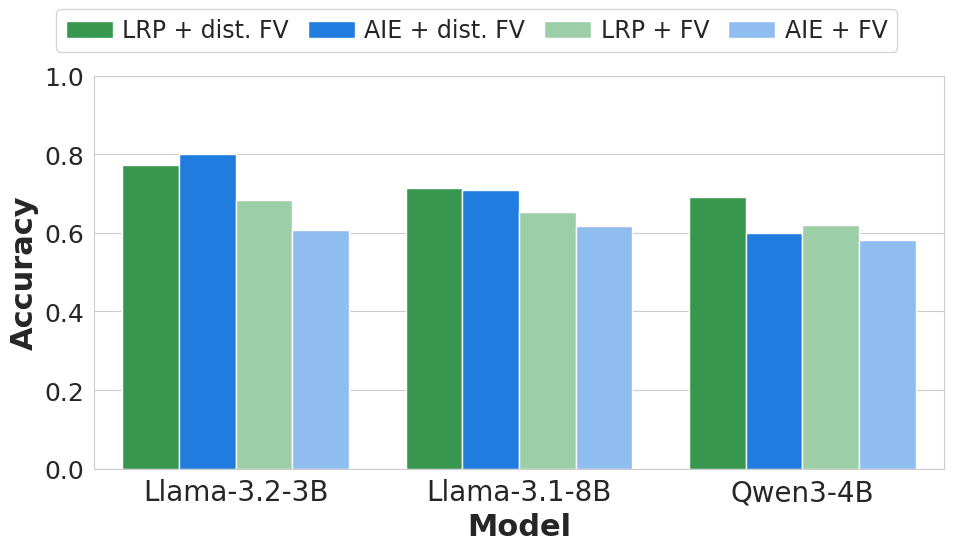

In [193]:
import os
import glob
import json
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def plot_average_results_across_models(
    model_configs,
    method_order=None,
    model_order=None,
    color_palette=None,
    output_name="average_eval_across_models.pdf"
):
    """
    Parses JSON files across multiple models and plots ONLY the overall average
    Top-1 accuracy for each method per model.
    """
    data_list = []

    # 1. Iterate through each model and its specific configuration
    for model_name, config in model_configs.items():
        base_dir = config['base_dir']
        method_map = config['runs']

        # Find all JSON files for this specific model
        all_json_files = glob.glob(os.path.join(base_dir, "**/*.json"), recursive=True)
        model_data = []

        for path in all_json_files:
            try:
                parts = path.split(os.sep)
                task_name = parts[-2]
                raw_run_name = os.path.splitext(parts[-1])[0]

                # Only process if this run is explicitly defined in the map for this model
                if raw_run_name not in method_map:
                    continue

                display_name = method_map[raw_run_name]

                with open(path, 'r') as f:
                    data = json.load(f)

                # Extract Top-1 Accuracy
                topk_data = data.get('intervention_topk', {})
                if not topk_data: continue

                first_key = list(topk_data.keys())[0]
                top1_accuracy = topk_data[first_key][0][1]

                model_data.append({
                    'Task': task_name,
                    'Method': display_name,
                    'Top-1 Accuracy': top1_accuracy
                })
            except Exception as e:
                print(f"Error processing {path}: {e}")

        # 2. Calculate average across tasks for this model
        if model_data:
            df_model = pd.DataFrame(model_data)
            # Group by Method to get the average
            avg_df = df_model.groupby('Method')['Top-1 Accuracy'].mean().reset_index()
            avg_df['Model'] = model_name
            data_list.append(avg_df)
        else:
            print(f"No valid data found for model: {model_name}")

    if not data_list:
        print("No data found across any models.")
        return

    # 3. Combine all models into one DataFrame
    combined_df = pd.concat(data_list, ignore_index=True)
    print(combined_df)

    # 4. Ensure Method order for the legend and bars
    if method_order:
        combined_df['Method'] = pd.Categorical(
            combined_df['Method'], categories=method_order, ordered=True
        )

    # Sort to keep things organized
    combined_df = combined_df.sort_values(['Model', 'Method'])

    # 5. Plotting
    # Adjusted figure size to be more suitable for scaling in a paper
    plt.figure(figsize=(10, 6))
    sns.set_style("whitegrid")

    plot = sns.barplot(
        data=combined_df,
        x='Model',
        y='Top-1 Accuracy',
        hue='Method',
        palette=color_palette,
        hue_order=method_order,
        order=model_order
    )

    plt.ylim(0, 1)

    # Increase label text sizes and make them bold
    plt.ylabel('Accuracy', fontsize=22, fontweight='bold')
    plt.xlabel('Model', fontsize=22, fontweight='bold')

    # Increase tick mark text sizes
    plt.xticks(fontsize=20)
    plt.yticks(fontsize=18)

    # Move legend to the top, set 2 columns (ncol=2), and increase text size
    plt.legend(
        bbox_to_anchor=(0.45, 1.03),  # Centered above the plot
        loc='lower center',
        ncol=4,                      # 2x2 grid
        #title='Methods',
        frameon=True,
        fontsize=17,                 # Larger legend text
        title_fontsize=16.5 ,           # Larger legend title text
        columnspacing=0.8,   # Space between columns (default is ~2.0)
        handletextpad=0.4,   # Space between the line/marker and the text (default is ~0.8)
        borderpad=0.4
    )

    plt.tight_layout()
    plt.savefig(output_name, dpi=300)
    print(f"Plot saved successfully as {output_name}")
    plt.show()

# --- Configuration ---

model_configs = {
    "Llama-3.2-3B": {
        "base_dir": f"{STORAGE_ROOT}/eval/Llama-3.2-3B-Instruct",
        "runs": {
            "prompt_dist_ie_averaged_scale1.0": "AIE + dist. FV",
            "prompt_dist_lrp_averaged_scale1.0": "LRP + dist. FV",
            "prompt_fv_ie_averaged_editlayer9_scale1.0": "AIE + FV",
            "prompt_fv_lrp_averaged_editlayer11_scale1.0": "LRP + FV"
        }
    },
    "Qwen3-4B": {
        "base_dir": f"{STORAGE_ROOT}/eval/Qwen3-4B-Instruct-2507",
        "runs": {
            "prompt_dist_ie_averaged_scale1.0": "AIE + dist. FV",
            "prompt_dist_lrp_averaged_scale1.0": "LRP + dist. FV",
            "prompt_fv_ie_averaged_editlayer21_scale1.0": "AIE + FV",
            "prompt_fv_lrp_averaged_editlayer19_scale1.0": "LRP + FV"
        }
    },
    "Llama-3.1-8B": {
        "base_dir": f"{STORAGE_ROOT}/eval/Llama-3.1-8B-Instruct",
        "runs": {
            "prompt_dist_ie_averaged_scale1.0": "AIE + dist. FV",
            "prompt_dist_lrp_averaged_scale1.0": "LRP + dist. FV",
            "prompt_fv_ie_averaged_editlayer15_scale1.0": "AIE + FV",
            "prompt_fv_lrp_averaged_editlayer12_scale1.0": "LRP + FV"
        }
    }
}

model_configs_pt = {
    "Llama-3.2-3B": {
        "base_dir": f"{STORAGE_ROOT}/eval/Llama-3.2-3B-Instruct",
        "runs": {
            "prompt_dist_ie_per_task_scale1.0": "AIE + dist. FV",
            "prompt_dist_lrp_per_task_scale1.0": "LRP + dist. FV",
            "prompt_fv_ie_per_task_editlayer9_scale1.0": "AIE + FV",
            "prompt_fv_lrp_per_task_editlayer11_scale1.0": "LRP + FV"
        }
    },
    "Qwen3-4B": {
        "base_dir": f"{STORAGE_ROOT}/eval/Qwen3-4B-Instruct-2507",
        "runs": {
            "prompt_dist_ie_per_task_scale1.0": "AIE + dist. FV",
            "prompt_dist_lrp_per_task_scale1.0": "LRP + dist. FV",
            "prompt_fv_ie_per_task_editlayer21_scale1.0": "AIE + FV",
            "prompt_fv_lrp_per_task_editlayer19_scale1.0": "LRP + FV"
        }
    },
    "Llama-3.1-8B": {
        "base_dir": f"{STORAGE_ROOT}/eval/Llama-3.1-8B-Instruct",
        "runs": {
            "prompt_dist_ie_per_task_scale1.0": "AIE + dist. FV",
            "prompt_dist_lrp_per_task_scale1.0": "LRP + dist. FV",
            "prompt_fv_ie_per_task_editlayer15_scale1.0": "AIE + FV",
            "prompt_fv_lrp_per_task_editlayer12_scale1.0": "LRP + FV"
        }
    }
}



my_order = [
        "LRP + dist. FV",
    "AIE + dist. FV",
        "LRP + FV",

    "AIE + FV",
]


my_colors = {
    "AIE + dist. FV": "#007BFF",  # Bright Electric Blue
    "LRP + dist. FV": "#28A745",  # Vibrant Leaf Green
    "AIE + FV":       "#80BCFF",  # Light Sky Blue
    "LRP + FV":       "#94D6A2"   # Light Mint Green
}

# --- Execution ---
plot_average_results_across_models(
    model_configs=model_configs_pt,
    method_order=my_order,
    model_order=my_model_order,
    color_palette=my_colors,
    output_name="average_eval_across_all_models_pt.pdf"
)

Plot saved successfully as per_task_eval_llama_3.2_8b_pt.pdf


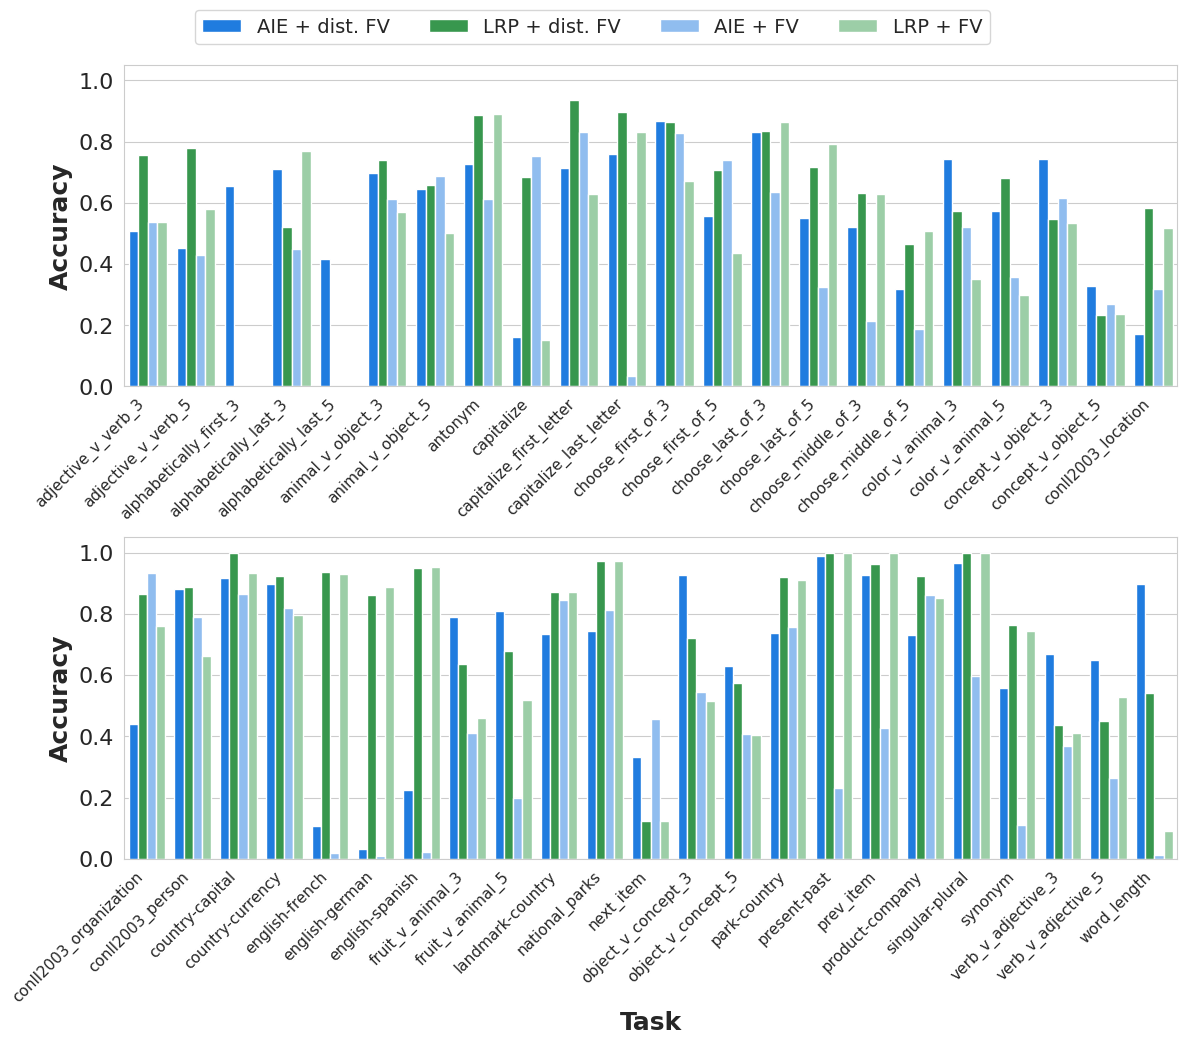

In [ ]:
import os
import glob
import json
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def plot_per_task_results_single_model(
    base_dir,
    method_map,
    method_order=None,
    color_palette=None,
    output_name="per_task_eval.png"
):
    """
    Parses JSON files for a SINGLE model and plots per-task Top-1 accuracy,
    split across 2 rows for readability.
    """
    data_list = []

    # 1. Find and parse all JSON files
    all_json_files = glob.glob(os.path.join(base_dir, "**/*.json"), recursive=True)

    for path in all_json_files:
        try:
            parts = path.split(os.sep)
            task_name = parts[-2]
            raw_run_name = os.path.splitext(parts[-1])[0]

            # Only process if this run is explicitly defined in the map
            if raw_run_name not in method_map:
                continue

            display_name = method_map[raw_run_name]

            with open(path, 'r') as f:
                data = json.load(f)

            # Extract Top-1 Accuracy
            topk_data = data.get('intervention_topk', {})
            if not topk_data: continue

            first_key = list(topk_data.keys())[0]
            top1_accuracy = topk_data[first_key][0][1]

            data_list.append({
                'Task': task_name,
                'Method': display_name,
                'Top-1 Accuracy': top1_accuracy
            })
        except Exception as e:
            print(f"Error processing {path}: {e}")

    if not data_list:
        print("No data found.")
        return

    # 2. Organize Data
    df = pd.DataFrame(data_list)

    if method_order:
        df['Method'] = pd.Categorical(
            df['Method'], categories=method_order, ordered=True
        )

    # Get sorted list of unique tasks and split them in half
    all_tasks = sorted(df['Task'].unique())
    midpoint = len(all_tasks) // 2
    tasks_top = all_tasks[:midpoint]
    tasks_bottom = all_tasks[midpoint:]

    # FIX: We sort values, but we DO NOT convert 'Task' to a global pd.Categorical
    df = df.sort_values(['Task', 'Method'])

    # Create distinct DataFrames for top and bottom to absolutely guarantee no overlap
    df_top = df[df['Task'].isin(tasks_top)].copy()
    df_bottom = df[df['Task'].isin(tasks_bottom)].copy()

    # 3. Plotting Setup (2 rows, 1 column)
    fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(12, 10))
    sns.set_style("whitegrid")

    # Top Row Plot
    sns.barplot(
        data=df_top,
        x='Task',
        y='Top-1 Accuracy',
        hue='Method',
        palette=color_palette,
        hue_order=method_order,
        order=tasks_top,
        ax=axes[0]
    )

    # Bottom Row Plot
    sns.barplot(
        data=df_bottom,
        x='Task',
        y='Top-1 Accuracy',
        hue='Method',
        palette=color_palette,
        hue_order=method_order,
        order=tasks_bottom,
        ax=axes[1]
    )

    # 4. Formatting Axes
    for i, ax in enumerate(axes):
        ax.set_ylim(0, 1.05)
        ax.set_ylabel('Accuracy', fontsize=18, fontweight='bold')

        # Only put the 'Task' label on the bottom x-axis to save space
        ax.set_xlabel('Task' if i == 1 else '', fontsize=18, fontweight='bold')

        # --- FIX: Align labels and make text smaller ---
        # Set explicitly to avoid Matplotlib warnings
        ax.set_xticks(ax.get_xticks())
        # Rotate 45 degrees, anchor text to the right side, reduce font to 11
        ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=11)

        ax.tick_params(axis='y', labelsize=16)

        # Remove the individual legends created by seaborn
        if ax.get_legend() is not None:
            ax.get_legend().remove()

    # 5. Global Legend (Centered at the very top of the figure)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles, labels,
        bbox_to_anchor=(0.5, 1.05), # Position relative to the figure
        loc='upper center',
        ncol=4,                     # 1x4 horizontal layout
        frameon=True,
        fontsize=14,
        title_fontsize=16
    )

    # Use bbox_inches='tight' to ensure the external legend and rotated labels aren't cut off
    plt.tight_layout()
    plt.savefig(output_name, dpi=300, bbox_inches='tight')
    print(f"Plot saved successfully as {output_name}")
    plt.show()


# --- Configuration ---

# Configuration for just ONE model
single_model_base_dir = f"{STORAGE_ROOT}/eval/Llama-3.1-8B-Instruct"

single_model_runs = {
    "prompt_dist_ie_averaged_scale1.0": "AIE + dist. FV",
    "prompt_dist_lrp_averaged_scale1.0": "LRP + dist. FV",
    "prompt_fv_ie_averaged_editlayer15_scale1.0": "AIE + FV",
    "prompt_fv_lrp_averaged_editlayer12_scale1.0": "LRP + FV"
}
single_model_runs_pt = {
    "prompt_dist_ie_per_task_scale1.0": "AIE + dist. FV",
    "prompt_dist_lrp_per_task_scale1.0": "LRP + dist. FV",
    "prompt_fv_ie_per_task_editlayer15_scale1.0": "AIE + FV",
    "prompt_fv_lrp_per_task_editlayer12_scale1.0": "LRP + FV"
}


my_order = [
    "AIE + dist. FV",
    "LRP + dist. FV",
    "AIE + FV",
    "LRP + FV"
]

my_colors = {
    "AIE + dist. FV": "#1f77b4",  # Dark Blue
    "LRP + dist. FV": "#ff7f0e",  # Dark Orange
    "AIE + FV":       "#a2c4e1",  # Light Blue
    "LRP + FV":       "#ffbb78"   # Light Orange
}

my_colors = {
    "AIE + dist. FV": "#007BFF",  # Bright Electric Blue
    "LRP + dist. FV": "#28A745",  # Vibrant Leaf Green
    "AIE + FV":       "#80BCFF",  # Light Sky Blue
    "LRP + FV":       "#94D6A2"   # Light Mint Green
}


# --- Execution ---
plot_per_task_results_single_model(
    base_dir=single_model_base_dir,
    method_map=single_model_runs,
    method_order=my_order,
    color_palette=my_colors,
    output_name="per_task_eval_llama_3.2_8b_pt.pdf"
)

Comparing top 20 GLOBAL heads...
  [warn] missing prompt IE for 'capitalize_second_letter', skipping
  [warn] missing prompt IE for 'lowercase_first_letter', skipping
  [warn] missing prompt IE for 'lowercase_last_letter', skipping
  [warn] missing prompt IE for 'next_capital_letter', skipping
  [warn] missing prompt IE for 'capitalize_second_letter', skipping
  [warn] missing prompt IE for 'lowercase_first_letter', skipping
  [warn] missing prompt IE for 'lowercase_last_letter', skipping
  [warn] missing prompt IE for 'next_capital_letter', skipping
Plot successfully saved as global_heads_atlas.pdf at 300 DPI


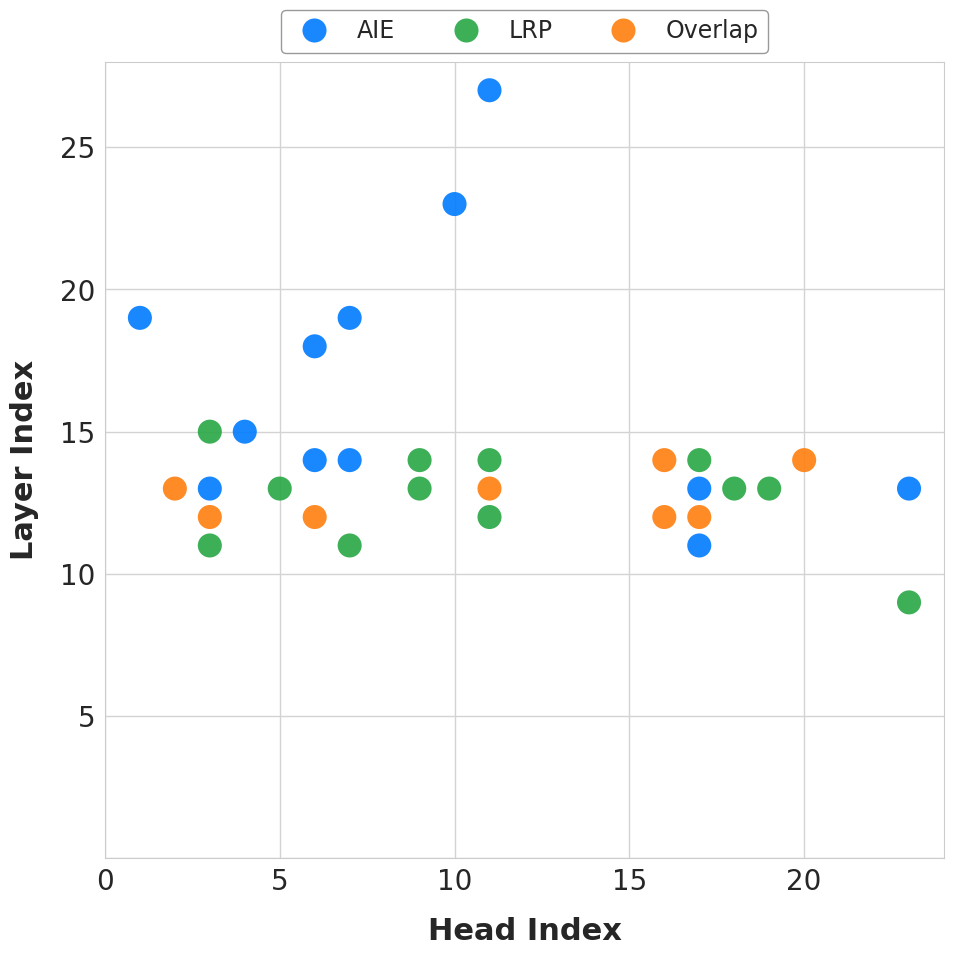

In [192]:
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ─── CONFIGURATION ────────────────────────────────────────────────────────────
STORAGE_ROOT = os.environ.get("FV_STORAGE_ROOT", "storage")
ROOT_DIR_1 = os.path.join(STORAGE_ROOT, "function_vectors", "full_results_prompt_based_short")
ROOT_DIR_2 = os.path.join(STORAGE_ROOT, "function_vectors", "full_results_prompt_based_short")

MODEL_SHORT = "Llama-3.2-3B-Instruct"
SELECTION_1 = "aie"
SELECTION_2 = "lrp"
TOPK_ATTN = 20

MODEL_LAYERS = 28
MODEL_HEADS = 24

TASKS = [
    # abstractive
    "antonym", "capitalize", "capitalize_first_letter", "capitalize_last_letter",
    "capitalize_second_letter",
    "country-capital", "country-currency", "english-french", "english-german", "english-spanish",
    "landmark-country", "lowercase_first_letter", "lowercase_last_letter", "national_parks",
    "next_capital_letter", "next_item", "park-country", "present-past", "prev_item",
    "product-company", "singular-plural", "synonym", "word_length",
    # extractive
    "adjective_v_verb_3", "adjective_v_verb_5",
    "alphabetically_last_3",
    "animal_v_object_3", "animal_v_object_5",
    "choose_first_of_3", "choose_first_of_5",
    "choose_last_of_3", "choose_last_of_5",
    "choose_middle_of_3", "choose_middle_of_5",
    "color_v_animal_3", "color_v_animal_5",
    "concept_v_object_3", "concept_v_object_5",
    "conll2003_location", "conll2003_organization", "conll2003_person",
    "fruit_v_animal_3", "fruit_v_animal_5",
    "object_v_concept_3", "object_v_concept_5",
    "verb_v_adjective_3", "verb_v_adjective_5",
]

def plot_global_heads_atlas(heads_1, heads_2, label_1="Path 1", label_2="Path 2",
                            depth=MODEL_LAYERS, width=MODEL_HEADS, title="Global Heads Atlas"):
    """Plots global heads with a shared (0,0) origin and margins only on top/right."""
    set1, set2 = set(heads_1), set(heads_2)
    intersection = set1.intersection(set2)
    only_1 = set1 - intersection
    only_2 = set2 - intersection

    data = []
    for l, h in only_1:
        data.append({'Layer': l, 'Head': h, 'Source': label_1})
    for l, h in only_2:
        data.append({'Layer': l, 'Head': h, 'Source': label_2})
    for l, h in intersection:
        data.append({'Layer': l, 'Head': h, 'Source': 'Overlap'})

    df = pd.DataFrame(data)

    if df.empty:
        print("No heads to plot!")
        return

    plt.figure(figsize=(10, 10))
    sns.set_style("whitegrid")



    palette = {
        label_1: '#007BFF',
        label_2: '#28A745',
        'Overlap': '#ff7f0e'
    }

    ax = sns.scatterplot(
        data=df,
        x='Head',
        y='Layer',
        hue='Source',
        s=300,
        alpha=0.9,
        palette=palette,
        edgecolor='none',
        linewidth=0
    )

    # ─── AXIS ALIGNMENT ───────────────────────────────────────────────────────

    # Pin the bottom and left to 0.
    # Add a small buffer to width/depth to create the requested top/right margin.
    plt.xlim(0, width )
    plt.ylim(0, depth )

    # Generate ticks: Start from 0, go up to the max index
    x_ticks = list(range(0, width, 5))
    y_ticks = list(range(0, depth, 5))

    # To have "only one 0", we'll set the ticks and then
    # remove the label for '0' on the Y-axis so it doesn't double up.
    ax.set_xticks(x_ticks)
    ax.set_yticks(y_ticks)

    # Use a custom formatter to hide the 0 on the Y-axis
    y_labels = [str(i) if i != 0 else "" for i in y_ticks]
    ax.set_yticklabels(y_labels, fontsize=20)
    plt.xticks(fontsize=20)

    # Grid and Aesthetics
    ax.set_axisbelow(True)
    ax.grid(True, color='lightgrey', linestyle='-', linewidth=1)

    plt.xlabel("Head Index", fontsize=22, labelpad=15, fontweight='bold')
    plt.ylabel("Layer Index", fontsize=22, labelpad=15, fontweight='bold')

    plt.legend(
        loc='upper center',
        bbox_to_anchor=(0.5, 1.08),
        ncol=3,
        fontsize=17,
        frameon=True,
        edgecolor='gray'
    )

    plt.tight_layout()

    # --- ADDED CODE TO SAVE AS 300 DPI PDF ---
    output_filename = "global_heads_atlas.pdf"
    plt.savefig(output_filename, format='pdf', dpi=300, bbox_inches='tight')
    print(f"Plot successfully saved as {output_filename} at 300 DPI")
    # -----------------------------------------

    plt.show()

    plt.show()
# ─── MAIN SCRIPT ──────────────────────────────────────────────────────────────

def main():
    # Adjust path to match project structure
    parent_dir = os.path.abspath('..')
    if parent_dir not in sys.path:
        sys.path.insert(0, parent_dir)

    from eval.utils import load_prompt_aie, select_modules

    print(f"Comparing top {TOPK_ATTN} GLOBAL heads...")

    try:
        # Load data
        aie_1 = load_prompt_aie(ROOT_DIR_1, MODEL_SHORT, TASKS, SELECTION_1)
        aie_2 = load_prompt_aie(ROOT_DIR_2, MODEL_SHORT, TASKS, SELECTION_2)

        # Select modules
        global_heads_1, _ = select_modules(aie_1, topk_attn=TOPK_ATTN)
        global_heads_2, _ = select_modules(aie_2, topk_attn=TOPK_ATTN)

        # Plot the heads
        plot_global_heads_atlas(
            global_heads_1,
            global_heads_2,
            label_1=SELECTION_1.upper(),
            label_2=SELECTION_2.upper(),
        )

    except Exception as e:
        print(f"[Error] Failed to calculate and plot: {e}")

if __name__ == "__main__":
    main()

In [ ]:
import matplotlib.pyplot as plt

def plot_paper_ready_data(data_dict):
    """
    Plots accuracy vs. samples per minute (log scale) formatted for an academic paper,
    with labels next to each data point and no legend.
    """
    # Set global styling for a clean, academic look
    plt.rcParams.update({
        'font.size': 12,
        'axes.titlesize': 14,
        'axes.labelsize': 12,
        'xtick.labelsize': 11,
        'ytick.labelsize': 11,
        'figure.autolayout': True
    })

    fig, ax = plt.subplots(figsize=(7, 5.5))

    # Iterate through the dictionary to plot each point
    for label, metrics in data_dict.items():
        accuracy = metrics['accuracy']
        spm = metrics['spm']
        color = metrics.get('color', 'blue')

        # Plot the scatter point
        # (Removed the 'label' argument since we are no longer using a legend)
        ax.scatter(
            accuracy,
            spm,
            color=color,
            s=150,
            edgecolors='black',
            linewidths=1.5,
            alpha=0.9,
            zorder=3
        )

        # Add the label next to the dot
        ax.annotate(
            label,
            (accuracy, spm),
            textcoords="offset points",
            xytext=(0, 12),
            ha='center',
            fontsize=10,
            fontweight='semibold',
            color='#333333',
            zorder=4
        )

    # Log scale for SPM
    ax.set_yscale('log')

    # Tighten axis limits
    ax.set_xlim(0.52, 0.85)
    ax.set_ylim(1, 3000)

    # Add descriptive labels
    ax.set_xlabel('Accuracy', fontweight='bold')
    ax.set_ylabel('Samples per Minute', fontweight='bold')

    # Grid styling
    ax.grid(True, which="major", linestyle="-", alpha=0.3, zorder=0)
    ax.grid(True, which="minor", linestyle=":", alpha=0.2, zorder=0)


    # Add "Better" Arrow
    ax.annotate(
        'More efficient  \n& faithful',
        xy=(0.77, 500),      # Arrowhead points here (Moved left from 0.83, down from 1000)
        xytext=(0.62, 15),    # Text box sits here (Moved left from 0.65, down from 15)
        arrowprops=dict(facecolor='gray', shrink=0.05, width=2, headwidth=8, alpha=0.5),
        fontsize=10, color='gray', style='italic', ha='center',
        bbox=dict(boxstyle="round,pad=0.3", edgecolor="none", facecolor="white", alpha=0.7)
    )

    # Save as a high-resolution image
    plt.savefig('Figure_1_Performance_Final.png', dpi=300, bbox_inches='tight')

    # Display the plot
    plt.show()

# --- Example Usage ---

if __name__ == "__main__":
    # Define your custom color scheme
    my_colors = {
        "AIE + dist. FV": "#1f77b4",  # Dark Blue
        "LRP + dist. FV": "#ff7f0e",  # Dark Orange
        "AIE + FV":       "#a2c4e1",  # Light Blue
        "LRP + FV":       "#ffbb78"   # Light Orange
    }

    # Map the colors directly to your data points
    sample_data = {
        'AIE + FV':        {'accuracy': 0.551947, 'spm': 4.65,  'color': my_colors['AIE + FV']},
        'AIE + dist. FV':  {'accuracy': 0.708205, 'spm': 4.65,  'color': my_colors['AIE + dist. FV']},
        'LRP + FV':        {'accuracy': 0.746358, 'spm': 549.6, 'color': my_colors['LRP + FV']},
        'LRP + dist. FV':  {'accuracy': 0.810051, 'spm': 549.6, 'color': my_colors['LRP + dist. FV']}
    }

    plot_paper_ready_data(sample_data)

/tmp/ipykernel_2353702/209781234.py:88: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.savefig('Figure_1_Performance_Broken_Axis.png', dpi=300, bbox_inches='tight')
.venv/lib64/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


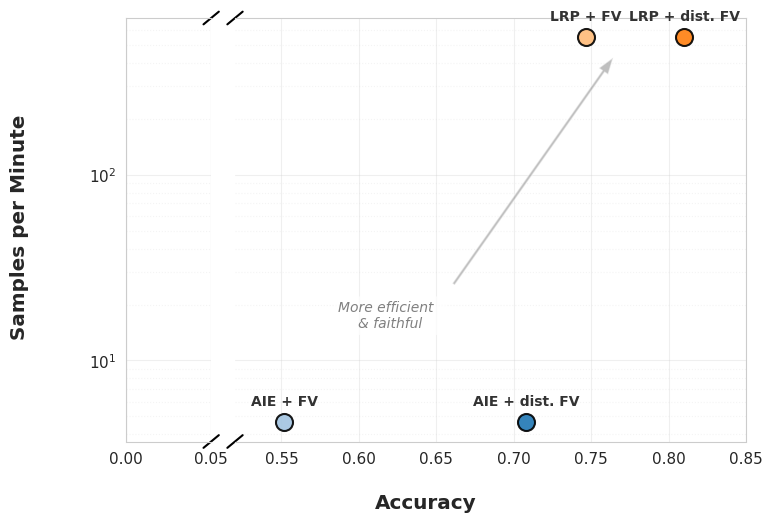

In [39]:
import matplotlib.pyplot as plt

def plot_paper_ready_data(data_dict):
    """
    Plots accuracy vs. samples per minute with a true 'broken' X-axis
    to properly show the jump from 0 to 0.52.
    """
    plt.rcParams.update({
        'font.size': 12,
        'axes.titlesize': 14,
        'axes.labelsize': 12,
        'xtick.labelsize': 11,
        'ytick.labelsize': 11,
    })

    # Create two side-by-side subplots with a small gap (wspace)
    # ax1 is the origin (0), ax2 is the main data.
    # width_ratios makes the right plot larger than the left plot.
    fig, (ax1, ax2) = plt.subplots(1, 2, sharey=True, figsize=(8, 5.5),
                                   gridspec_kw={'width_ratios': [1, 6], 'wspace': 0.08})

    for ax in (ax1, ax2):
        # Plot data on both axes (xlim will handle what is actually visible)
        for label, metrics in data_dict.items():
            accuracy = metrics['accuracy']
            spm = metrics['spm']
            color = metrics.get('color', 'blue')

            ax.scatter(accuracy, spm, color=color, s=150, edgecolors='black',
                       linewidths=1.5, alpha=0.9, zorder=3)

            # Only annotate on the right plot (ax2) where the dots actually sit
            if ax == ax2:
                ax.annotate(label, (accuracy, spm), textcoords="offset points",
                            xytext=(0, 12), ha='center', fontsize=10,
                            fontweight='semibold', color='#333333', zorder=4)

        ax.set_yscale('log')

    # Set limits to create the "cut"
    ax1.set_xlim(0, 0.05)     # Left plot just shows the zero mark
    ax2.set_xlim(0.52, 0.85)  # Right plot houses your actual data

    # Grid styling (Keep horizontal lines continuous, but remove vertical lines from the empty left plot)
    ax1.grid(True, axis='y', which="major", linestyle="-", alpha=0.3, zorder=0)
    ax1.grid(True, axis='y', which="minor", linestyle=":", alpha=0.2, zorder=0)
    ax2.grid(True, which="both", linestyle="-", alpha=0.3, zorder=0)
    ax2.grid(True, which="minor", linestyle=":", alpha=0.2, zorder=0)

    # --- HIDE SPINES TO CREATE THE BREAK ---
    ax1.spines['right'].set_visible(False)
    ax2.spines['left'].set_visible(False)

    # Clean up overlapping ticks
    ax1.tick_params(right=False)
    ax2.tick_params(left=False)

    # --- ADD THE DIAGONAL MARKS (//) ---
    d = 0.015  # Size of the diagonal lines

    # Left plot marks (We multiply the X-coordinate 'd' by 6 because ax1 is 1/6th the width of ax2,
    # this ensures the diagonal angle matches perfectly between the two sides)
    kwargs_ax1 = dict(transform=ax1.transAxes, color='black', clip_on=False, linewidth=1.5)
    ax1.plot((1 - d*6, 1 + d*6), (-d, +d), **kwargs_ax1)                 # Bottom right
    ax1.plot((1 - d*6, 1 + d*6), (1 - d, 1 + d), **kwargs_ax1)           # Top right

    # Right plot marks
    kwargs_ax2 = dict(transform=ax2.transAxes, color='black', clip_on=False, linewidth=1.5)
    ax2.plot((-d, +d), (-d, +d), **kwargs_ax2)                           # Bottom left
    ax2.plot((-d, +d), (1 - d, 1 + d), **kwargs_ax2)                     # Top left

    # --- GLOBAL LABELS ---
    # Because we have two subplots, we use fig.supxlabel/ylabel to center the text across both
    fig.supxlabel('Accuracy', fontweight='bold', y=-0.02)
    fig.supylabel('Samples per Minute', fontweight='bold', x=-0.02)

    # Add "Better" Arrow to the main data plot (ax2)
    ax2.annotate(
        'More efficient  \n& faithful',
        xy=(0.77, 500),
        xytext=(0.62, 15),
        arrowprops=dict(facecolor='gray', shrink=0.05, width=2, headwidth=8, alpha=0.5),
        fontsize=10, color='gray', style='italic', ha='center',
        bbox=dict(boxstyle="round,pad=0.3", edgecolor="none", facecolor="white", alpha=0.7)
    )

    # Save and display
    plt.savefig('Figure_1_Performance_Broken_Axis.png', dpi=300, bbox_inches='tight')
    plt.show()

# --- Example Usage ---

if __name__ == "__main__":
    my_colors = {
        "AIE + dist. FV": "#1f77b4",
        "LRP + dist. FV": "#ff7f0e",
        "AIE + FV":       "#a2c4e1",
        "LRP + FV":       "#ffbb78"
    }

    sample_data = {
        'AIE + FV':        {'accuracy': 0.551947, 'spm': 4.65,  'color': my_colors['AIE + FV']},
        'AIE + dist. FV':  {'accuracy': 0.708205, 'spm': 4.65,  'color': my_colors['AIE + dist. FV']},
        'LRP + FV':        {'accuracy': 0.746358, 'spm': 549.6, 'color': my_colors['LRP + FV']},
        'LRP + dist. FV':  {'accuracy': 0.810051, 'spm': 549.6, 'color': my_colors['LRP + dist. FV']}
    }

    plot_paper_ready_data(sample_data)

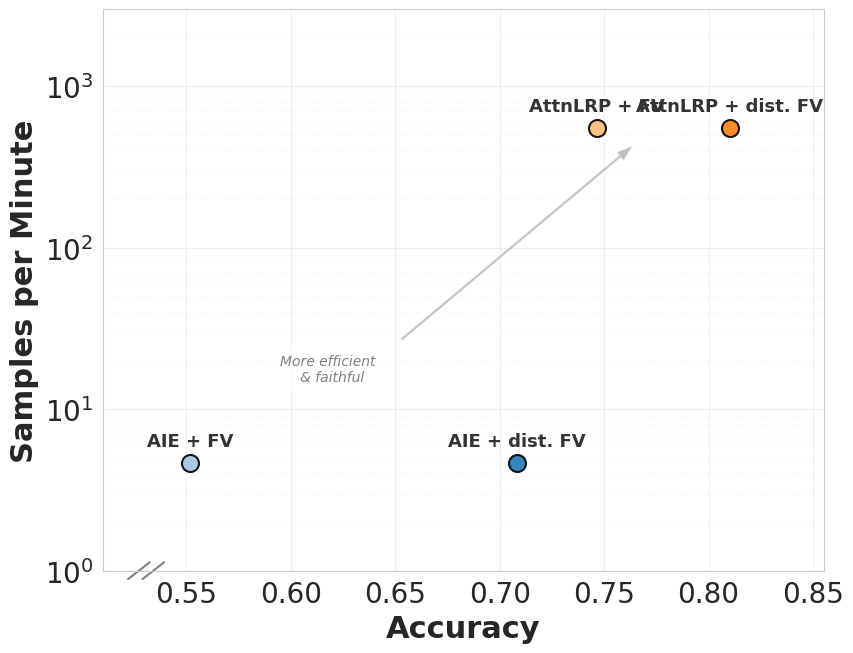

In [118]:
import matplotlib.pyplot as plt

def plot_paper_ready_data(data_dict):
    """
    Plots accuracy vs. samples per minute (log scale) formatted for an academic paper,
    with labels next to each data point and no legend. Includes axis break marks.
    """

    sns.set_style("whitegrid")
    # Set global styling for a clean, academic look
    plt.rcParams.update({
        'font.size': 22,
        'axes.titlesize': 22,
        'axes.labelsize': 22,
        'xtick.labelsize': 20,
        'ytick.labelsize': 20,
        'figure.autolayout': True
    })

    fig, ax = plt.subplots(figsize=(9, 7))

    # Iterate through the dictionary to plot each point
    for label, metrics in data_dict.items():
        accuracy = metrics['accuracy']
        spm = metrics['spm']
        color = metrics.get('color', 'blue')

        # Plot the scatter point
        ax.scatter(
            accuracy,
            spm,
            color=color,
            s=150,
            edgecolors='black',
            linewidths=1.5,
            alpha=0.9,
            zorder=3
        )

        # Add the label next to the dot
        ax.annotate(
            label,
            (accuracy, spm),
            textcoords="offset points",
            xytext=(0, 12),
            ha='center',
            fontsize=13,
            fontweight='semibold',
            color='#333333',
            zorder=4
        )

    # Log scale for SPM
    ax.set_yscale('log')

    # Tighten axis limits
    ax.set_xlim(0.51, 0.855)
    ax.set_ylim(1, 3000)

    # --- NEW: Add Axis Break Marks (//) to appease the plot police ---
    d = 0.015  # Size of the diagonal lines
    x_offset = 0.05# How far to move the lines to the right

    # kwargs for the lines: use axes coordinates (transAxes), changed color to gray
    kwargs = dict(transform=ax.transAxes, color='gray', clip_on=False, linewidth=1.5)

    # Draw the double slash // on the X-axis (shifted right by x_offset)
    ax.plot([-d + x_offset, d + x_offset], [-d, d], **kwargs)                      # First line
    ax.plot([-d + 0.02 + x_offset, d + 0.02 + x_offset], [-d, d], **kwargs)        # Second line shifted right
    # -----------------------------------------------------------------

    # Add descriptive labels
    ax.set_xlabel('Accuracy', fontweight='bold')
    ax.set_ylabel('Samples per Minute', fontweight='bold')

    # Grid styling
    ax.grid(True, which="major", linestyle="-", alpha=0.3, zorder=0)
    ax.grid(True, which="minor", linestyle=":", alpha=0.2, zorder=0)

    # Add "Better" Arrow
    ax.annotate(
        'More efficient  \n& faithful',
        xy=(0.77, 500),
        xytext=(0.62, 15),
        arrowprops=dict(facecolor='gray', shrink=0.05, width=2, headwidth=8, alpha=0.5),
        fontsize=10, color='gray', style='italic', ha='center',
        bbox=dict(boxstyle="round,pad=0.3", edgecolor="none", facecolor="white", alpha=0.7)
    )

    # Save as a high-resolution image
    plt.savefig('Figure_1_Performance_Final.png', dpi=300, bbox_inches='tight')

    # Display the plot
    plt.show()

# --- Example Usage ---

if __name__ == "__main__":
    # Define your custom color scheme
    my_colors = {
        "AIE + dist. FV": "#1f77b4",  # Dark Blue
        "AttnLRP + dist. FV": "#ff7f0e",  # Dark Orange
        "AIE + FV":       "#a2c4e1",  # Light Blue
        "AttnLRP + FV":       "#ffbb78"   # Light Orange
    }

    # Map the colors directly to your data points
    sample_data = {
        'AIE + FV':        {'accuracy': 0.551947, 'spm': 4.65,  'color': my_colors['AIE + FV']},
        'AIE + dist. FV':  {'accuracy': 0.708205, 'spm': 4.65,  'color': my_colors['AIE + dist. FV']},
        'AttnLRP + FV':        {'accuracy': 0.746358, 'spm': 549.6, 'color': my_colors['AttnLRP + FV']},
        'AttnLRP + dist. FV':  {'accuracy': 0.810051, 'spm': 549.6, 'color': my_colors['AttnLRP + dist. FV']}
    }

    plot_paper_ready_data(sample_data)

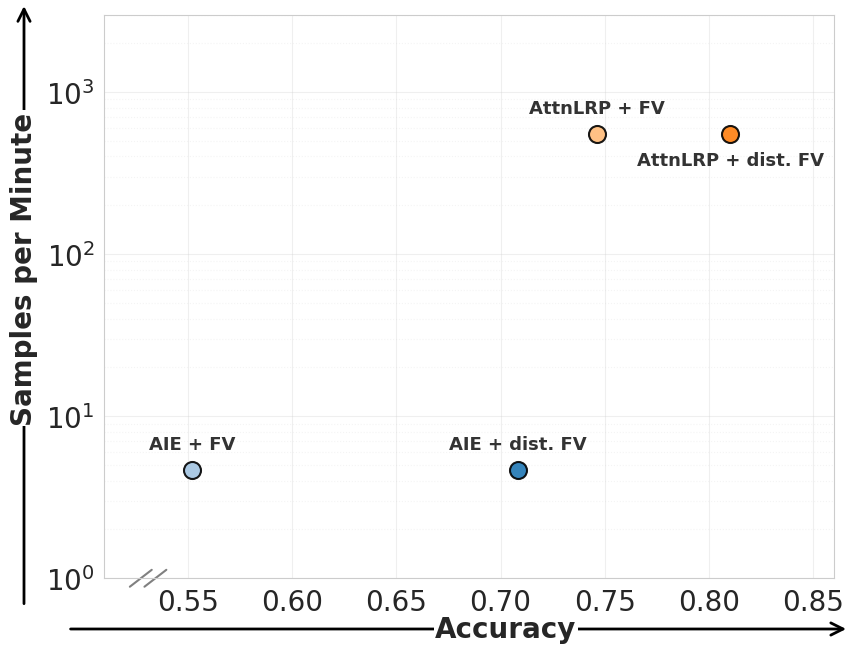

In [133]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_paper_ready_data(data_dict):
    """
    Plots accuracy vs. samples per minute (log scale) formatted for an academic paper.
    Arrows are extended further to the left and bottom.
    """

    sns.set_style("whitegrid")
    plt.rcParams.update({
        'font.size': 22,
        'axes.titlesize': 22,
        'axes.labelsize': 22,
        'xtick.labelsize': 20,
        'ytick.labelsize': 20,
        'figure.autolayout': True
    })

    fig, ax = plt.subplots(figsize=(9, 7))

    for label, metrics in data_dict.items():
        accuracy = metrics['accuracy']
        spm = metrics['spm']
        color = metrics.get('color', 'blue')

        ax.scatter(
            accuracy, spm,
            color=color, s=150, edgecolors='black',
            linewidths=1.5, alpha=0.9, zorder=3
        )

        # Label placement logic
        xy_offset = (0, 12)
        v_align = 'bottom'
        if label == "AttnLRP + dist. FV":
            xy_offset = (0, -12)
            v_align = 'top'

        ax.annotate(
            label, (accuracy, spm),
            textcoords="offset points", xytext=xy_offset,
            ha='center', va=v_align,
            fontsize=13, fontweight='semibold', color='#333333',
            zorder=4
        )

    ax.set_yscale('log')
    ax.set_xlim(0.51, 0.86)
    ax.set_ylim(1, 3000)

    # --- Axis Break Marks (//) ---
    d = 0.015
    x_offset = 0.05
    break_kwargs = dict(transform=ax.transAxes, color='gray', clip_on=False, linewidth=1.5)
    ax.plot([-d + x_offset, d + x_offset], [-d, d], **break_kwargs)
    ax.plot([-d + 0.02 + x_offset, d + 0.02 + x_offset], [-d, d], **break_kwargs)

    # --- Arrows passing through labels (Extended) ---
    ax.set_xlabel('', labelpad=0)
    ax.set_ylabel('', labelpad=0)

    # X-axis Arrow and Label (xytext changed to -0.05 to extend left)
    x_arrow_y = -0.09
    ax.annotate('', xy=(1.02, x_arrow_y), xycoords='axes fraction', xytext=(-0.05, x_arrow_y),
                arrowprops=dict(arrowstyle="->", color='black', lw=2), clip_on=False)

    ax.text(0.55, x_arrow_y, 'Accuracy', transform=ax.transAxes,
            ha='center', va='center', fontweight='bold', fontsize=20,
            bbox=dict(facecolor='white', edgecolor='none', pad=1))

    # Y-axis Arrow and Label (xytext y-coord changed to -0.05 to extend down)
    y_arrow_x = -0.11
    ax.annotate('', xy=(y_arrow_x, 1.02), xycoords='axes fraction', xytext=(y_arrow_x, -0.05),
                arrowprops=dict(arrowstyle="->", color='black', lw=2), clip_on=False)

    ax.text(y_arrow_x, 0.55, 'Samples per Minute', transform=ax.transAxes,
            ha='center', va='center', fontweight='bold', fontsize=20, rotation=90,
            bbox=dict(facecolor='white', edgecolor='none', pad=1))

    ax.grid(True, which="major", linestyle="-", alpha=0.3, zorder=0)
    ax.grid(True, which="minor", linestyle=":", alpha=0.2, zorder=0)

    plt.savefig('Figure_1_Performance_Final.png', dpi=300, bbox_inches='tight')
    plt.show()

if __name__ == "__main__":
    my_colors = {
        "AIE + dist. FV": "#1f77b4",
        "AttnLRP + dist. FV": "#ff7f0e",
        "AIE + FV":       "#a2c4e1",
        "AttnLRP + FV":       "#ffbb78"
    }

    sample_data = {
        'AIE + FV':            {'accuracy': 0.551947, 'spm': 4.65,  'color': my_colors['AIE + FV']},
        'AIE + dist. FV':      {'accuracy': 0.708205, 'spm': 4.65,  'color': my_colors['AIE + dist. FV']},
        'AttnLRP + FV':        {'accuracy': 0.746358, 'spm': 549.6, 'color': my_colors['AttnLRP + FV']},
        'AttnLRP + dist. FV':  {'accuracy': 0.810051, 'spm': 549.6, 'color': my_colors['AttnLRP + dist. FV']}
    }

    plot_paper_ready_data(sample_data)

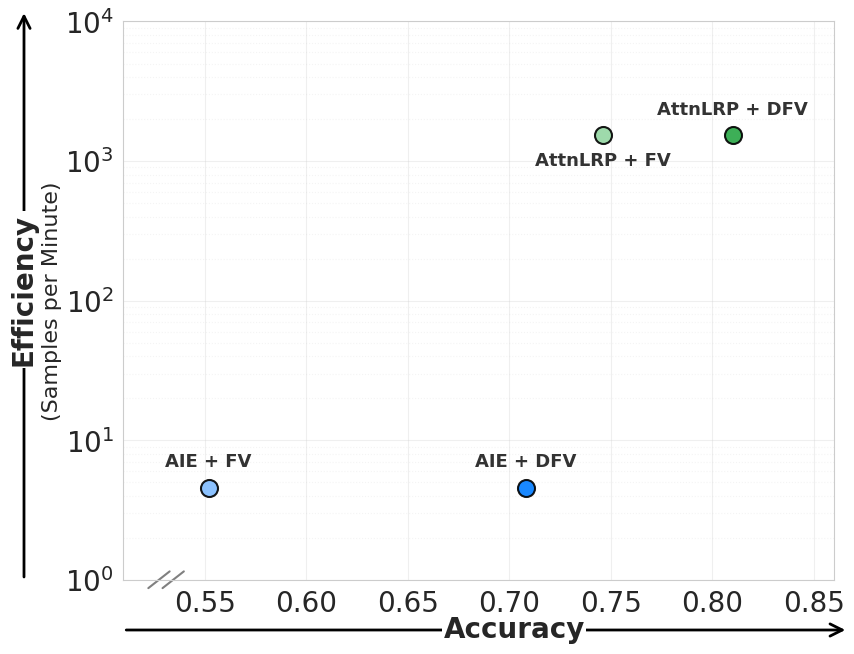

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_paper_ready_data(data_dict):
    """
    Plots accuracy vs. samples per minute (log scale).
    Updated: Y-axis arrow extends through 'Efficiency', with units placed below.
    """

    sns.set_style("whitegrid")
    plt.rcParams.update({
        'font.size': 22,
        'axes.titlesize': 22,
        'axes.labelsize': 22,
        'xtick.labelsize': 20,
        'ytick.labelsize': 20,
        'figure.autolayout': True
    })

    fig, ax = plt.subplots(figsize=(9, 7))

    for label, metrics in data_dict.items():
        accuracy = metrics['accuracy']
        spm = metrics['spm']
        color = metrics.get('color', 'blue')

        ax.scatter(
            accuracy, spm,
            color=color, s=150, edgecolors='black',
            linewidths=1.5, alpha=0.9, zorder=3
        )

        # Label placement logic (AttnLRP + FV moved below marker)
        xy_offset = (0, 12)
        v_align = 'bottom'
        if label == "AttnLRP + FV":
            xy_offset = (0, -12)
            v_align = 'top'

        ax.annotate(
            label, (accuracy, spm),
            textcoords="offset points", xytext=xy_offset,
            ha='center', va=v_align,
            fontsize=13, fontweight='semibold', color='#333333',
            zorder=4
        )

    ax.set_yscale('log')
    ax.set_xlim(0.51, 0.86)
    ax.set_ylim(1, 10000)

    # --- Axis Break Marks (//) ---
    d = 0.015
    x_offset = 0.05
    break_kwargs = dict(transform=ax.transAxes, color='gray', clip_on=False, linewidth=1.5)
    ax.plot([-d + x_offset, d + x_offset], [-d, d], **break_kwargs)
    ax.plot([-d + 0.02 + x_offset, d + 0.02 + x_offset], [-d, d], **break_kwargs)

    # --- Arrows and Labels ---
    ax.set_xlabel('', labelpad=0)
    ax.set_ylabel('', labelpad=0)

    # X-axis Arrow and Label
    x_arrow_y = -0.09
    ax.annotate('', xy=(1.02, x_arrow_y), xycoords='axes fraction', xytext=(-0.0, x_arrow_y),
                arrowprops=dict(arrowstyle="->", color='black', lw=2), clip_on=False)

    ax.text(0.55, x_arrow_y, 'Accuracy', transform=ax.transAxes,
            ha='center', va='center', fontweight='bold', fontsize=20,
            bbox=dict(facecolor='white', edgecolor='none', pad=1))

    # Y-axis Arrow and Label
    y_arrow_x = -0.14
    # Arrow starts at 0.15 (leaving space for units below) and goes to 1.02
    ax.annotate('', xy=(y_arrow_x, 1.02), xycoords='axes fraction', xytext=(y_arrow_x, 0.0
                                                                ),
                arrowprops=dict(arrowstyle="->", color='black', lw=2), clip_on=False)

    # Primary Label: Bold, on the arrow
    ax.text(y_arrow_x, 0.52, 'Efficiency', transform=ax.transAxes,
            ha='center', va='center', fontweight='bold', fontsize=20, rotation=90,
            bbox=dict(facecolor='white', edgecolor='none', pad=2))

    # Secondary Label: Normal weight, smaller, below the arrow start
    ax.text(y_arrow_x+0.04, 0.5, '(Samples per Minute)', transform=ax.transAxes,
            ha='center', va='center', fontweight='normal', fontsize=16, rotation=90)

    ax.grid(True, which="major", linestyle="-", alpha=0.3, zorder=0)
    ax.grid(True, which="minor", linestyle=":", alpha=0.2, zorder=0)

    plt.savefig('Figure_1_Performance_Final_dfv.png', dpi=300, bbox_inches='tight')
    plt.show()

if __name__ == "__main__":
    my_colors = {
        "AIE + dist. FV": "#1f77b4",
        "AttnLRP + dist. FV": "#ff7f0e",
        "AIE + FV":       "#a2c4e1",
        "AttnLRP + FV":       "#ffbb78"
    }
    my_colors = {
    "AIE + dist. FV": "#007BFF",  # Bright Electric Blue
    "AttnLRP + dist. FV": "#28A745",  # Vibrant Leaf Green
    "AIE + FV":       "#80BCFF",  # Light Sky Blue
    "AttnLRP + FV":       "#94D6A2"   # Light Mint Green
}

    sample_data = {
        'AIE + FV':            {'accuracy': 0.551947, 'spm': 4.573,  'color': my_colors['AIE + FV']},
        'AIE + DFV':      {'accuracy': 0.708205, 'spm': 4.573,  'color': my_colors['AIE + dist. FV']},
        'AttnLRP + FV':        {'accuracy': 0.746358, 'spm': 1541.9, 'color': my_colors['AttnLRP + FV']},
        'AttnLRP + DFV':  {'accuracy': 0.810051, 'spm': 1541.9, 'color': my_colors['AttnLRP + dist. FV']}
    }

    plot_paper_ready_data(sample_data)

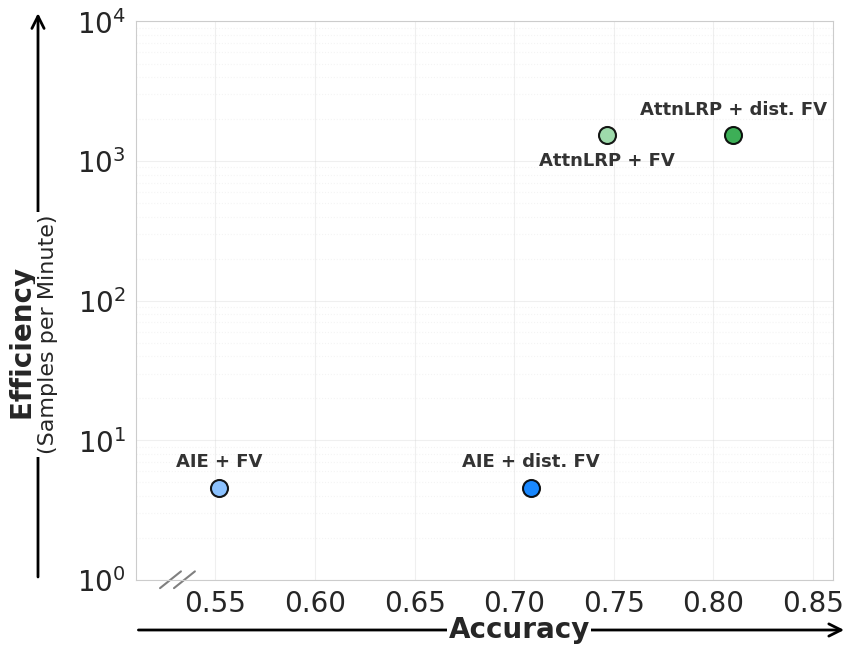

In [182]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_paper_ready_data(data_dict):
    """
    Plots accuracy vs. samples per minute (log scale).
    Updated: Y-axis label "Samples per Minute" moved to the same line as "Efficiency",
    but kept smaller and not bold.
    """

    sns.set_style("whitegrid")
    plt.rcParams.update({
        'font.size': 22,
        'axes.titlesize': 22,
        'axes.labelsize': 22,
        'xtick.labelsize': 20,
        'ytick.labelsize': 20,
        'figure.autolayout': True
    })

    fig, ax = plt.subplots(figsize=(9, 7))

    for label, metrics in data_dict.items():
        accuracy = metrics['accuracy']
        spm = metrics['spm']
        color = metrics.get('color', 'blue')

        ax.scatter(
            accuracy, spm,
            color=color, s=150, edgecolors='black',
            linewidths=1.5, alpha=0.9, zorder=3
        )

        # Label placement logic (AttnLRP + FV moved below marker)
        xy_offset = (0, 12)
        v_align = 'bottom'
        if label == "AttnLRP + FV":
            xy_offset = (0, -12)
            v_align = 'top'

        ax.annotate(
            label, (accuracy, spm),
            textcoords="offset points", xytext=xy_offset,
            ha='center', va=v_align,
            fontsize=13, fontweight='semibold', color='#333333',
            zorder=4
        )

    ax.set_yscale('log')
    ax.set_xlim(0.51, 0.86)
    ax.set_ylim(1, 10000)

    # --- Axis Break Marks (//) ---
    d = 0.015
    x_offset = 0.05
    break_kwargs = dict(transform=ax.transAxes, color='gray', clip_on=False, linewidth=1.5)
    ax.plot([-d + x_offset, d + x_offset], [-d, d], **break_kwargs)
    ax.plot([-d + 0.02 + x_offset, d + 0.02 + x_offset], [-d, d], **break_kwargs)

    # --- Arrows and Labels ---
    ax.set_xlabel('', labelpad=0)
    ax.set_ylabel('', labelpad=0)

    # X-axis Arrow and Label
    x_arrow_y = -0.09
    ax.annotate('', xy=(1.02, x_arrow_y), xycoords='axes fraction', xytext=(-0.0, x_arrow_y),
                arrowprops=dict(arrowstyle="->", color='black', lw=2), clip_on=False)

    ax.text(0.55, x_arrow_y, 'Accuracy', transform=ax.transAxes,
            ha='center', va='center', fontweight='bold', fontsize=20,
            bbox=dict(facecolor='white', edgecolor='none', pad=1))

    # Y-axis Arrow and Label
    y_arrow_x = -0.14
    # Arrow starts at 0.0 to span the full edge
    ax.annotate('', xy=(y_arrow_x, 1.02), xycoords='axes fraction', xytext=(y_arrow_x, 0.0),
                arrowprops=dict(arrowstyle="->", color='black', lw=2), clip_on=False)

    # --- Y-Axis Text Alignment ---
    # Using the exact same X coordinate, and anchoring them together at y=0.44.
    # ha='right' pushes "Efficiency" to the bottom, ha='left' pushes "(Samples...)" to the top.
    split_y_coord = 0.44

    # Primary Label (Efficiency): Bold, size 20
    # Note: added a double space at the end to provide natural padding between the words.
    ax.text(y_arrow_x, split_y_coord, 'Efficiency  ', transform=ax.transAxes,
            ha='right', va='center', fontweight='bold', fontsize=20, rotation=90,
            bbox=dict(facecolor='white', edgecolor='none', pad=2))

    # Secondary Label (Samples per Minute): Normal weight, size 16
    ax.text(y_arrow_x, split_y_coord, '(Samples per Minute)', transform=ax.transAxes,
            ha='left', va='center', fontweight='normal', fontsize=16, rotation=90,
            bbox=dict(facecolor='white', edgecolor='none', pad=2))

    ax.grid(True, which="major", linestyle="-", alpha=0.3, zorder=0)
    ax.grid(True, which="minor", linestyle=":", alpha=0.2, zorder=0)

    plt.savefig('Figure_1_Performance_Final.png', dpi=300, bbox_inches='tight')
    plt.show()

if __name__ == "__main__":
    my_colors = {
        "AIE + dist. FV": "#007BFF",  # Bright Electric Blue
        "AttnLRP + dist. FV": "#28A745",  # Vibrant Leaf Green
        "AIE + FV":       "#80BCFF",  # Light Sky Blue
        "AttnLRP + FV":       "#94D6A2"   # Light Mint Green
    }

    sample_data = {
        'AIE + FV':            {'accuracy': 0.551947, 'spm': 4.573,  'color': my_colors['AIE + FV']},
        'AIE + dist. FV':      {'accuracy': 0.708205, 'spm': 4.573,  'color': my_colors['AIE + dist. FV']},
        'AttnLRP + FV':        {'accuracy': 0.746358, 'spm': 1541.9, 'color': my_colors['AttnLRP + FV']},
        'AttnLRP + dist. FV':  {'accuracy': 0.810051, 'spm': 1541.9, 'color': my_colors['AttnLRP + dist. FV']}
    }

    plot_paper_ready_data(sample_data)

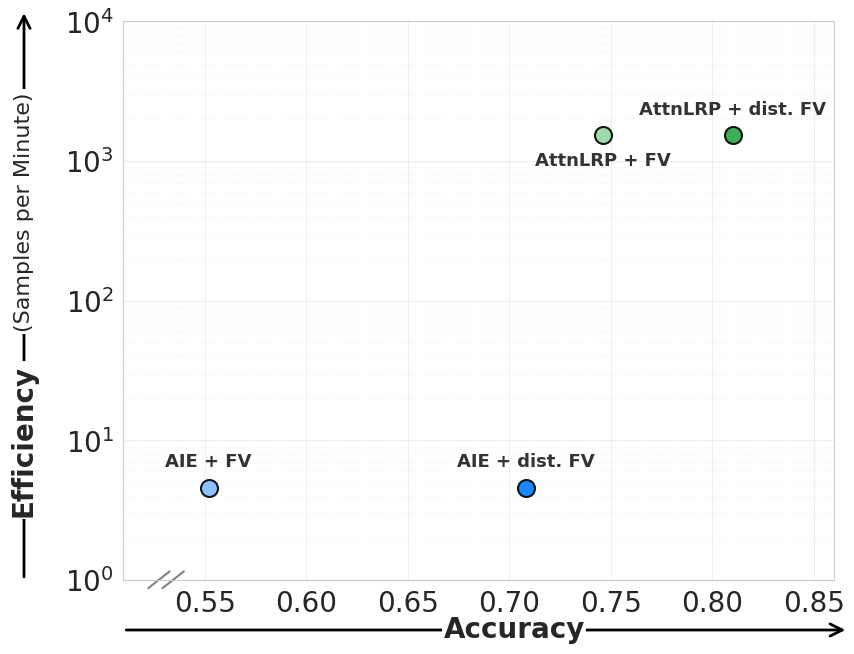

In [184]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_paper_ready_data(data_dict):
    """
    Plots accuracy vs. samples per minute (log scale).
    Updated: Y-axis label explicitly aligned to form a single continuous line.
    """

    sns.set_style("whitegrid")
    plt.rcParams.update({
        'font.size': 22,
        'axes.titlesize': 22,
        'axes.labelsize': 22,
        'xtick.labelsize': 20,
        'ytick.labelsize': 20,
        'figure.autolayout': True
    })

    fig, ax = plt.subplots(figsize=(9, 7))

    for label, metrics in data_dict.items():
        accuracy = metrics['accuracy']
        spm = metrics['spm']
        color = metrics.get('color', 'blue')

        ax.scatter(
            accuracy, spm,
            color=color, s=150, edgecolors='black',
            linewidths=1.5, alpha=0.9, zorder=3
        )

        # Label placement logic
        xy_offset = (0, 12)
        v_align = 'bottom'
        if label == "AttnLRP + FV":
            xy_offset = (0, -12)
            v_align = 'top'

        ax.annotate(
            label, (accuracy, spm),
            textcoords="offset points", xytext=xy_offset,
            ha='center', va=v_align,
            fontsize=13, fontweight='semibold', color='#333333',
            zorder=4
        )

    ax.set_yscale('log')
    ax.set_xlim(0.51, 0.86)
    ax.set_ylim(1, 10000)

    # --- Axis Break Marks (//) ---
    d = 0.015
    x_offset = 0.05
    break_kwargs = dict(transform=ax.transAxes, color='gray', clip_on=False, linewidth=1.5)
    ax.plot([-d + x_offset, d + x_offset], [-d, d], **break_kwargs)
    ax.plot([-d + 0.02 + x_offset, d + 0.02 + x_offset], [-d, d], **break_kwargs)

    # --- Arrows and Labels ---
    ax.set_xlabel('', labelpad=0)
    ax.set_ylabel('', labelpad=0)

    # X-axis Arrow and Label
    x_arrow_y = -0.09
    ax.annotate('', xy=(1.02, x_arrow_y), xycoords='axes fraction', xytext=(-0.0, x_arrow_y),
                arrowprops=dict(arrowstyle="->", color='black', lw=2), clip_on=False)

    ax.text(0.55, x_arrow_y, 'Accuracy', transform=ax.transAxes,
            ha='center', va='center', fontweight='bold', fontsize=20,
            bbox=dict(facecolor='white', edgecolor='none', pad=1))

    # Y-axis Arrow
    y_arrow_x = -0.14
    ax.annotate('', xy=(y_arrow_x, 1.02), xycoords='axes fraction', xytext=(y_arrow_x, 0.0),
                arrowprops=dict(arrowstyle="->", color='black', lw=2), clip_on=False)

    # --- Y-Axis Text Alignment (Single Line) ---
    # Both texts use ha='center' on the exact same X coordinate so they form a perfect vertical line.

    # 1. "Efficiency" (Bold, size 20, lower on the axis)
    ax.text(y_arrow_x, 0.25, 'Efficiency', transform=ax.transAxes,
            ha='center', va='center', fontweight='bold', fontsize=20, rotation=90,
            bbox=dict(facecolor='white', edgecolor='none', pad=2))

    # 2. "(Samples per Minute)" (Normal, size 16, directly above Efficiency)
    ax.text(y_arrow_x, 0.66, '(Samples per Minute)', transform=ax.transAxes,
            ha='center', va='center', fontweight='normal', fontsize=16, rotation=90,
            bbox=dict(facecolor='white', edgecolor='none', pad=2))

    ax.grid(True, which="major", linestyle="-", alpha=0.3, zorder=0)
    ax.grid(True, which="minor", linestyle=":", alpha=0.2, zorder=0)

    plt.savefig('Figure_1_Performance_Final.png', dpi=300, bbox_inches='tight')
    plt.show()

if __name__ == "__main__":
    my_colors = {
        "AIE + dist. FV": "#007BFF",
        "AttnLRP + dist. FV": "#28A745",
        "AIE + FV":       "#80BCFF",
        "AttnLRP + FV":       "#94D6A2"
    }

    sample_data = {
        'AIE + FV':            {'accuracy': 0.551947, 'spm': 4.573,  'color': my_colors['AIE + FV']},
        'AIE + dist. FV':      {'accuracy': 0.708205, 'spm': 4.573,  'color': my_colors['AIE + dist. FV']},
        'AttnLRP + FV':        {'accuracy': 0.746358, 'spm': 1541.9, 'color': my_colors['AttnLRP + FV']},
        'AttnLRP + dist. FV':  {'accuracy': 0.810051, 'spm': 1541.9, 'color': my_colors['AttnLRP + dist. FV']}
    }

    plot_paper_ready_data(sample_data)

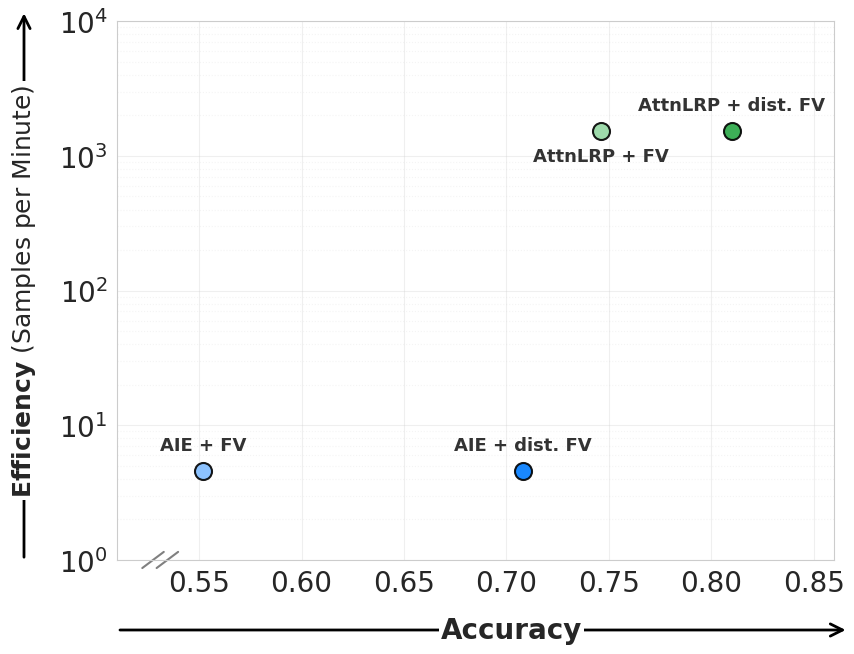

In [189]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_paper_ready_data(data_dict):
    """
    Plots accuracy vs. samples per minute (log scale).
    Updated: Y-axis label combined into a single ax.text using MathText.
    """

    sns.set_style("whitegrid")
    plt.rcParams.update({
        'font.size': 22,
        'axes.titlesize': 22,
        'axes.labelsize': 22,
        'xtick.labelsize': 20,
        'ytick.labelsize': 20,
        'figure.autolayout': True,
        'mathtext.default': 'regular' # Ensures math text matches regular font style
    })

    fig, ax = plt.subplots(figsize=(9, 7))

    for label, metrics in data_dict.items():
        accuracy = metrics['accuracy']
        spm = metrics['spm']
        color = metrics.get('color', 'blue')

        ax.scatter(
            accuracy, spm,
            color=color, s=150, edgecolors='black',
            linewidths=1.5, alpha=0.9, zorder=3
        )

        # Label placement logic
        xy_offset = (0, 12)
        v_align = 'bottom'
        if label == "AttnLRP + FV":
            xy_offset = (0, -12)
            v_align = 'top'

        ax.annotate(
            label, (accuracy, spm),
            textcoords="offset points", xytext=xy_offset,
            ha='center', va=v_align,
            fontsize=13, fontweight='semibold', color='#333333',
            zorder=4
        )

    ax.set_yscale('log')
    ax.set_xlim(0.51, 0.86)
    ax.set_ylim(1, 10000)

    # --- Axis Break Marks (//) ---
    d = 0.015
    x_offset = 0.05
    break_kwargs = dict(transform=ax.transAxes, color='gray', clip_on=False, linewidth=1.5)
    ax.plot([-d + x_offset, d + x_offset], [-d, d], **break_kwargs)
    ax.plot([-d + 0.02 + x_offset, d + 0.02 + x_offset], [-d, d], **break_kwargs)

    # --- Arrows and Labels ---
    ax.set_xlabel('', labelpad=0)
    ax.set_ylabel('', labelpad=0)

    # X-axis Arrow and Label
    x_arrow_y = -0.13
    ax.annotate('', xy=(1.02, x_arrow_y), xycoords='axes fraction', xytext=(-0.0, x_arrow_y),
                arrowprops=dict(arrowstyle="->", color='black', lw=2), clip_on=False)

    ax.text(0.55, x_arrow_y, 'Accuracy', transform=ax.transAxes,
            ha='center', va='center', fontweight='bold', fontsize=20,
            bbox=dict(facecolor='white', edgecolor='none', pad=1))

    # Y-axis Arrow
    y_arrow_x = -0.13
    ax.annotate('', xy=(y_arrow_x, 1.02), xycoords='axes fraction', xytext=(y_arrow_x, 0.0),
                arrowprops=dict(arrowstyle="->", color='black', lw=2), clip_on=False)

    # --- Y-Axis Text Alignment (Single Line via MathText) ---
    # Using \mathbf{} to bold 'Efficiency', leaving the rest as normal text.
    ax.text(y_arrow_x, 0.5, r"$\mathbf{Efficiency}$ (Samples per Minute)", transform=ax.transAxes,
            ha='center', va='center', fontsize=18, rotation=90,
            bbox=dict(facecolor='white', edgecolor='none', pad=2))

    ax.grid(True, which="major", linestyle="-", alpha=0.3, zorder=0)
    ax.grid(True, which="minor", linestyle=":", alpha=0.2, zorder=0)

    plt.savefig('Figure_1_Performance_Final.png', dpi=300, bbox_inches='tight')
    plt.show()

if __name__ == "__main__":
    my_colors = {
        "AIE + dist. FV": "#007BFF",
        "AttnLRP + dist. FV": "#28A745",
        "AIE + FV":       "#80BCFF",
        "AttnLRP + FV":       "#94D6A2"
    }

    sample_data = {
        'AIE + FV':            {'accuracy': 0.551947, 'spm': 4.573,  'color': my_colors['AIE + FV']},
        'AIE + dist. FV':      {'accuracy': 0.708205, 'spm': 4.573,  'color': my_colors['AIE + dist. FV']},
        'AttnLRP + FV':        {'accuracy': 0.746358, 'spm': 1541.9, 'color': my_colors['AttnLRP + FV']},
        'AttnLRP + dist. FV':  {'accuracy': 0.810051, 'spm': 1541.9, 'color': my_colors['AttnLRP + dist. FV']}
    }

    plot_paper_ready_data(sample_data)

In [ ]:
import os
import glob
import json
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def plot_average_results_across_models(
    model_configs,
    method_order=None,
    model_order=None,
    color_palette=None,
    output_name="average_eval_across_models.pdf"
):
    """
    Parses JSON files across multiple models and plots ONLY the overall average
    Top-1 accuracy for each method per model.
    """
    data_list = []

    # 1. Iterate through each model and its specific configuration
    for model_name, config in model_configs.items():
        base_dir = config['base_dir']
        method_map = config['runs']

        # Find all JSON files for this specific model
        all_json_files = glob.glob(os.path.join(base_dir, "**/*.json"), recursive=True)
        model_data = []

        for path in all_json_files:
            try:
                parts = path.split(os.sep)
                task_name = parts[-2]
                raw_run_name = os.path.splitext(parts[-1])[0]

                # Only process if this run is explicitly defined in the map for this model
                if raw_run_name not in method_map:
                    continue

                display_name = method_map[raw_run_name]

                with open(path, 'r') as f:
                    data = json.load(f)

                # Extract Top-1 Accuracy
                topk_data = data.get('intervention_topk', {})
                if not topk_data: continue

                first_key = list(topk_data.keys())[0]
                top1_accuracy = topk_data[first_key][0][1]

                model_data.append({
                    'Task': task_name,
                    'Method': display_name,
                    'Top-1 Accuracy': top1_accuracy
                })
            except Exception as e:
                print(f"Error processing {path}: {e}")

        # 2. Calculate average across tasks for this model
        if model_data:
            df_model = pd.DataFrame(model_data)
            # Group by Method to get the average
            avg_df = df_model.groupby('Method')['Top-1 Accuracy'].mean().reset_index()
            avg_df['Model'] = model_name
            data_list.append(avg_df)
        else:
            print(f"No valid data found for model: {model_name}")

    if not data_list:
        print("No data found across any models.")
        return

    # 3. Combine all models into one DataFrame
    combined_df = pd.concat(data_list, ignore_index=True)
    print(combined_df)

    # 4. Ensure Method order for the legend and bars
    if method_order:
        combined_df['Method'] = pd.Categorical(
            combined_df['Method'], categories=method_order, ordered=True
        )

    # Sort to keep things organized
    combined_df = combined_df.sort_values(['Model', 'Method'])

    # 5. Plotting
    # Adjusted figure size slightly to accommodate 8 bars per model comfortably
    plt.figure(figsize=(12, 6))
    sns.set_style("whitegrid")

    plot = sns.barplot(
        data=combined_df,
        x='Model',
        y='Top-1 Accuracy',
        hue='Method',
        palette=color_palette,
        hue_order=method_order,
        order=model_order
    )

    plt.ylim(0, 1)

    # Increase label text sizes and make them bold
    plt.ylabel('Accuracy', fontsize=22, fontweight='bold')
    plt.xlabel('Model', fontsize=22, fontweight='bold')

    # Increase tick mark text sizes
    plt.xticks(fontsize=20)
    plt.yticks(fontsize=18)

    # Legend configured for 8 items (4 columns, 2 rows)
    plt.legend(
        bbox_to_anchor=(0.5, 1.05),  # Lifted slightly to fit 2 rows
        loc='lower center',
        ncol=4,                      # 4x2 grid to fit the 8 methods cleanly
        frameon=True,
        fontsize=14,                 # Slightly smaller to fit "Top-40" text
        title_fontsize=16.5,
        columnspacing=0.8,
        handletextpad=0.4,
        borderpad=0.4
    )

    plt.tight_layout()
    plt.savefig(output_name, dpi=300)
    print(f"Plot saved successfully as {output_name}")
    plt.show()


# --- Configuration ---

# Added the topk40 runs for each modelmodel_configs = {
    "Llama-3.2-3B": {
        "base_dir": f"{STORAGE_ROOT}/eval/Llama-3.2-3B-Instruct",
        "runs": {
            "prompt_dist_ie_averaged_scale1.0": "AIE + dist. FV",
            "prompt_dist_lrp_averaged_scale1.0": "LRP + dist. FV",
            "prompt_fv_ie_averaged_editlayer9_scale1.0": "AIE + FV",
            "prompt_fv_lrp_averaged_editlayer11_scale1.0": "LRP + FV",

            # Top-40 counterparts
            "prompt_dist_ie_averaged_topk40_scale1.0": "AIE + dist. FV (Top-40)",
            "prompt_dist_lrp_averaged_topk40_scale1.0": "LRP + dist. FV (Top-40)",
            "prompt_fv_ie_averaged_topk40_editlayer9_scale1.0": "AIE + FV (Top-40)",
            "prompt_fv_lrp_averaged_topk40_editlayer11_scale1.0": "LRP + FV (Top-40)"
        }
    },
    "Qwen3-4B": {
        "base_dir": f"{STORAGE_ROOT}/eval/Qwen3-4B-Instruct-2507",
        "runs": {
            "prompt_dist_ie_averaged_scale1.0": "AIE + dist. FV",
            "prompt_dist_lrp_averaged_scale1.0": "LRP + dist. FV",
            "prompt_fv_ie_averaged_editlayer21_scale1.0": "AIE + FV",
            "prompt_fv_lrp_averaged_editlayer19_scale1.0": "LRP + FV",

            # Top-40 counterparts
            "prompt_dist_ie_averaged_topk40_scale1.0": "AIE + dist. FV (Top-40)",
            "prompt_dist_lrp_averaged_topk40_scale1.0": "LRP + dist. FV (Top-40)",
            "prompt_fv_ie_averaged_topk40_editlayer21_scale1.0": "AIE + FV (Top-40)",
            "prompt_fv_lrp_averaged_topk40_editlayer19_scale1.0": "LRP + FV (Top-40)"
        }
    },
    "Llama-3.1-8B": {
        "base_dir": f"{STORAGE_ROOT}/eval/Llama-3.1-8B-Instruct",
        "runs": {
            "prompt_dist_ie_averaged_scale1.0": "AIE + dist. FV",
            "prompt_dist_lrp_averaged_scale1.0": "LRP + dist. FV",
            "prompt_fv_ie_averaged_editlayer15_scale1.0": "AIE + FV",
            "prompt_fv_lrp_averaged_editlayer12_scale1.0": "LRP + FV",

            # Top-40 counterparts
            "prompt_dist_ie_averaged_topk40_scale1.0": "AIE + dist. FV (Top-40)",
            "prompt_dist_lrp_averaged_topk40_scale1.0": "LRP + dist. FV (Top-40)",
            "prompt_fv_ie_averaged_topk40_editlayer15_scale1.0": "AIE + FV (Top-40)",
            "prompt_fv_lrp_averaged_topk40_editlayer12_scale1.0": "LRP + FV (Top-40)"
        }
    }
}
}

# Ordered to group methods together visually (Original next to its Top-40 counterpart)
my_order = [
    "LRP + dist. FV", "LRP + dist. FV (Top-40)",
    "AIE + dist. FV", "AIE + dist. FV (Top-40)",
    "LRP + FV",       "LRP + FV (Top-40)",
    "AIE + FV",       "AIE + FV (Top-40)"
]

# Created darker/bolder shades for the Top-40 runs to visually link them to their original counterparts
my_colors = {
    "AIE + dist. FV":          "#007BFF",  # Bright Electric Blue
    "AIE + dist. FV (Top-40)": "#004085",  # Dark Blue
    "LRP + dist. FV":          "#28A745",  # Vibrant Leaf Green
    "LRP + dist. FV (Top-40)": "#145523",  # Dark Green
    "AIE + FV":                "#80BCFF",  # Light Sky Blue
    "AIE + FV (Top-40)":       "#2c7ee6",  # Medium Blue
    "LRP + FV":                "#94D6A2",  # Light Mint Green
    "LRP + FV (Top-40)":       "#479958"   # Medium Green
}

# Ensure model order matches your keys
my_model_order = ["Llama-3.2-3B", "Qwen3-4B", "Llama-3.1-8B"]

# --- Execution ---
plot_average_results_across_models(
    model_configs=model_configs,        # Fixed variable name
    method_order=my_order,
    model_order=my_model_order,         # Fixed variable name
    color_palette=my_colors,
    output_name="average_eval_across_all_models_pt_top40_comparison.pdf"
)